<a href="https://colab.research.google.com/github/Stecklert1/stecklert1.github.io/blob/main/Practicum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/drive/MyDrive/payroll-2025.csv")

df.head()

,Hash1,Hash2,Birth Year,Gender,Race,Pay Grade,FLSA Status,EEOJ Code,Employment Type,Department ID,Department Name,Status,Year,Date Position Began,Date Position Ended,Annual Base Salary,Gross Pay,Base Pay,Overtime Pay,Other Pay
0,C99E0C04311A1FBD86A68E01527B3D4F9CFAF656,8FBD6E88FE846F798156B53582A07FE68C24D5D8,1955,Female,Black or African American,15,Non-Exempt,B: Professionals,Full Time,1600,Municipal Courts,Withdrawn,2025,01/01/2025,01/02/2025,51667.0,1286.61,1192.32,0.0,94.29
1,F224E67D62558473D8FD5F0332489905C592CDB5,4F2E3C274FFDC92F8436C9E15BF42DEDA1B62DEA,1955,Female,White,20,Exempt,B: Professionals,Full Time,3600,Parks & Recreation,Withdrawn,2025,01/01/2025,01/02/2025,67337.0,1890.61,1812.91,0.0,77.70
2,097646E986686B036D654E005F9581BE32377675,D9EFEE57EBA8157AAEBE1FC9B3EAEBD0348C7652,1963,Male,Black or African American,27,Exempt,B: Professionals,Full Time,1000,Police,Withdrawn,2025,01/01/2025,01/02/2025,117620.0,98009.09,3166.68,0.0,94842.41
3,2010C72D5CEE0AE8FA62F194DCEA2C1BAF1211A0,A4B01138B5CF79624949F94BDAE9366E6469F5E8,1973,Male,Black or African American,06,Non-Exempt,H: Service/Maintenance,Full Time,2000,Houston Public Works,Withdrawn,2025,01/01/2025,01/02/2025,37794.0,2178.38,1090.20,290.3,797.88
4,51A39920542A5C29D48B4EE8955CAEB3F7FF5322,50FAA8C948DD01067D238331EABD3E888DFE1033,1959,Male,Black or African American,13,Non-Exempt,H: Service/Maintenance,Full Time,2100,Solid Waste Management,Withdrawn,2025,01/01/2025,01/02/2025,58386.0,20728.21,1571.92,0.0,19156.29


In [2]:
df.shape


(26928, 20)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26928 entries, 0 to 26927
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Hash1                26928 non-null  object 
 1   Hash2                26928 non-null  object 
 2   Birth Year           26928 non-null  int64  
 3   Gender               26928 non-null  object 
 4   Race                 26928 non-null  object 
 5   Pay Grade            26928 non-null  object 
 6   FLSA Status          26928 non-null  object 
 7   EEOJ Code            26928 non-null  object 
 8   Employment Type      26928 non-null  object 
 9   Department ID        26928 non-null  int64  
 10  Department Name      26928 non-null  object 
 11  Status               26928 non-null  object 
 12  Year                 26928 non-null  int64  
 13  Date Position Began  26928 non-null  object 
 14  Date Position Ended  4571 non-null   object 
 15  Annual Base Salary   26928 non-null 

In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Hash1,26928,24396,5A0974FFB6F9D21D67120C309379B0F04A027A9A,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Hash2,26928,26928,8FBD6E88FE846F798156B53582A07FE68C24D5D8,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Birth Year,26928.0,NaN,NaN,NaN,1981.147282,13.094603,1900.0,1971.0,1982.0,1992.0,2010.0
Gender,26928,2,Male,18623,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Race,26928,9,Black or African American,9690,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pay Grade,26928,218,13,1728,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FLSA Status,26928,2,Non-Exempt,22055,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EEOJ Code,26928,8,D: Protective Service Workers,9618,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Employment Type,26928,4,Full Time,25375,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Department ID,26928.0,NaN,NaN,NaN,2332.616607,1871.947773,1000.0,1000.0,1500.0,2800.0,9000.0


In [5]:
missing = (
    df.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing_values")
)

missing["missing_percent"] = (
    missing["missing_values"] / len(df) * 100
)

missing

,missing_values,missing_percent
Date Position Ended,22357,83.025104
Hash1,0,0.000000
Birth Year,0,0.000000
Hash2,0,0.000000
Gender,0,0.000000
Race,0,0.000000
FLSA Status,0,0.000000
Pay Grade,0,0.000000
Employment Type,0,0.000000
Department ID,0,0.000000


In [6]:
active_employees_df = df[df['Status'] == 'Active'].copy()
display(active_employees_df.head())
display(active_employees_df.shape)

,Hash1,Hash2,Birth Year,Gender,Race,Pay Grade,FLSA Status,EEOJ Code,Employment Type,Department ID,Department Name,Status,Year,Date Position Began,Date Position Ended,Annual Base Salary,Gross Pay,Base Pay,Overtime Pay,Other Pay
28,F2C513A8CA13983115BD09E7FF32D326A0A80350,5C98B752D764C5E1AC94C27F9E65906D18DB56FE,1997,Female,Hispanic/Latino,05,Non-Exempt,H: Service/Maintenance,Temporary,2800,Houston Airport System,Active,2025,01/01/2025,NaN,36088.0,4832.05,3999.18,74.01,758.86
29,72FE5D78EB6BCDD1D68A736EDFA127168F6921C9,1480B48B7B23BC4A727973B01FC99E453B149954,1960,Female,White,34,Exempt,A: Officials & Administrators,Full Time,5000,Mayor's Office,Active,2025,01/02/2024,01/17/2025,186595.0,303781.17,14353.44,0.00,289427.73
30,69A6A52FD287B9B11857ADDD1FFD8831B041BC22,506E9990556C30C19B0ACF529371FC44553806C3,1955,Female,Black or African American,38,Exempt,A: Officials & Administrators,Full Time,1600,Municipal Courts,Active,2025,01/02/2024,NaN,203000.0,23966.07,21080.67,0.00,2885.40
32,78B0C927E5C5FFC0C9897B13B0A1926F83F11618,D31691023E92142D6FAE408807DEF376CE19F889,1998,Female,Hispanic/Latino,23,Exempt,B: Professionals,Full Time,5500,City Council,Active,2025,01/02/2024,NaN,76016.0,5850.38,5847.38,0.00,3.00
35,4AE6BA61FEBFD3F2506C22E7479CFC13890F5C64,124370C8F73748E49B41D40FBC11701437973844,1965,Male,White,PA04 - 17,Non-Exempt,D: Protective Service Workers,Full Time,1000,Police,Active,2025,01/03/2025,01/03/2025,91995.0,4014.60,3538.27,0.00,476.33


(24239, 20)

,count,mean,median,min,max
Pay Grade,,,,,
13,1728,45498.425926,44803.0,589.0,71011.0
10,1370,44632.153285,44408.0,33114.0,54226.0
PA04 - 17,1197,100736.335004,101195.0,88884.0,101195.0
17,930,57317.215054,57626.0,639.0,78187.0
16,881,54205.876277,53206.0,42557.0,80538.0
18,781,66652.265045,67725.0,712.0,85010.0
22,758,74686.678100,73424.0,837.0,120000.0
26,651,95846.015361,95815.0,75816.0,148016.0
20,644,66493.043478,64938.0,53612.0,110781.0


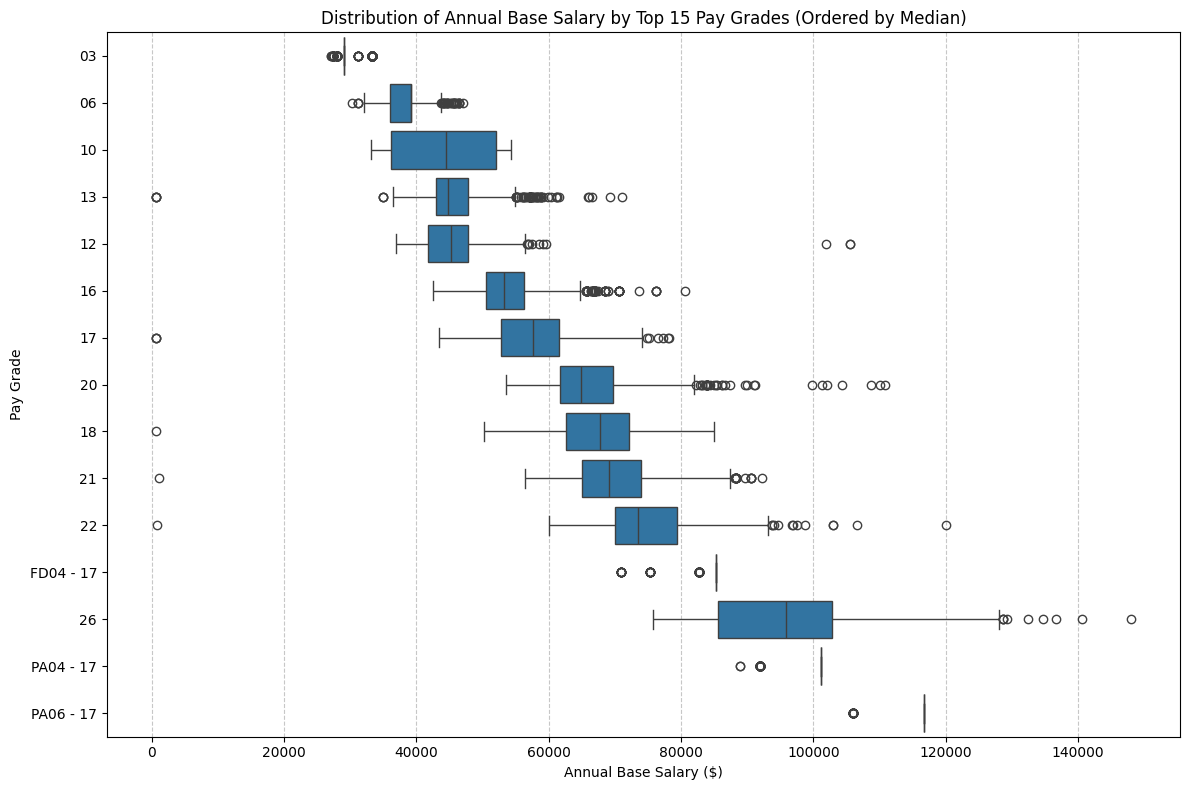

In [7]:
# Group by 'Pay Grade' and analyze the distribution of 'Annual Base Salary'
pay_grade_salary_stats = df.groupby('Pay Grade')['Annual Base Salary'].agg(['count', 'mean', 'median', 'min', 'max'])

# Display the top 15 pay grades by count to see typical distributions
display(pay_grade_salary_stats.sort_values(by='count', ascending=False).head(15))

# Let's visualize this relationship for the top 15 most common pay grades
top_pay_grades = df['Pay Grade'].value_counts().head(15).index
df_top_pg = df[df['Pay Grade'].isin(top_pay_grades)]

# Sort pay grades by their median salary for a cleaner progression in the plot
pg_order = df_top_pg.groupby('Pay Grade')['Annual Base Salary'].median().sort_values().index

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))
sns.boxplot(data=df_top_pg, x='Annual Base Salary', y='Pay Grade', order=pg_order)
plt.title('Distribution of Annual Base Salary by Top 15 Pay Grades (Ordered by Median)')
plt.xlabel('Annual Base Salary ($)')
plt.ylabel('Pay Grade')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [8]:
import pandas as pd

# Filter 'Pay Grade' to keep only numeric values between 4 and 39
# We convert to numeric where possible, coercing errors to NaN, and then filter
numeric_pg = pd.to_numeric(df['Pay Grade'], errors='coerce')
df_filtered_pg = df[numeric_pg.between(4, 39)].copy()

# Verify the filtered pay grades
print("Unique pay grades after filtering (4 to 39):")
print(sorted(df_filtered_pg['Pay Grade'].unique(), key=lambda x: int(x)))
print(f"\nNumber of rows remaining: {len(df_filtered_pg)}")

Unique pay grades after filtering (4 to 39):
['04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39']

Number of rows remaining: 15394


In [9]:
import re

def simplify_pay_grade(pg):
    if pd.isna(pg):
        return 'Unknown'
    pg_str = str(pg).strip()

    # Check if there is a hyphenated structure like 'PA04 - 17' or 'FD04 - 17'
    # Often, the last part ('17') indicates the broad/equivalent pay band,
    # or the first number ('04') indicates the sub-grade. Let's extract both or fallback.
    match = re.search(r'\d+', pg_str)
    if match:
        # Extract the first consecutive sequence of digits as a fallback base numerical category
        return f"Grade_{int(match.group())}"

    return pg_str

# Apply simplification
df['Simplified_Pay_Grade'] = df['Pay Grade'].apply(simplify_pay_grade)

original_count = df['Pay Grade'].nunique()
reduced_count = df['Simplified_Pay_Grade'].nunique()

print(f"Original unique pay grades: {original_count}")
print(f"Reduced unique pay grades: {reduced_count}")
print("\nTop 20 Simplified Pay Grades by Frequency:")
display(df['Simplified_Pay_Grade'].value_counts().head(20))

Original unique pay grades: 218
Reduced unique pay grades: 41

Top 20 Simplified Pay Grades by Frequency:


,count
Simplified_Pay_Grade,
Grade_3,4760
Grade_4,2980
Grade_6,1873
Grade_13,1728
Grade_10,1374
Grade_5,1165
Grade_17,932
Grade_16,881
Grade_22,852


Correlation between Pay Grade and Annual Base Salary (Grades 4-39): 0.8596


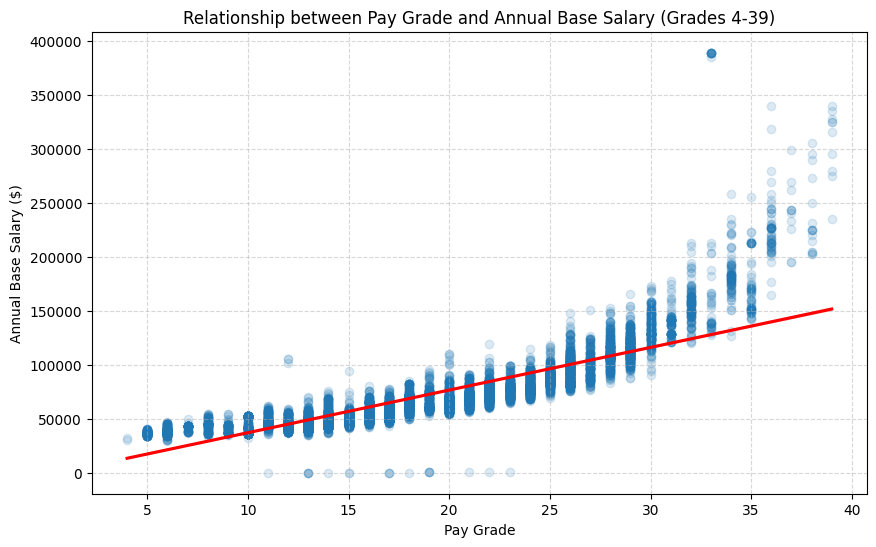

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure pay grade is treated as a numeric column for correlation analysis
df_filtered_pg['Pay Grade Numeric'] = pd.to_numeric(df_filtered_pg['Pay Grade'])

# Calculate correlation
correlation = df_filtered_pg['Pay Grade Numeric'].corr(df_filtered_pg['Annual Base Salary'])
print(f"Correlation between Pay Grade and Annual Base Salary (Grades 4-39): {correlation:.4f}")

# Visualize the relationship with a scatter plot and regression line
plt.figure(figsize=(10, 6))
sns.regplot(data=df_filtered_pg, x='Pay Grade Numeric', y='Annual Base Salary', scatter_kws={'alpha':0.15}, line_kws={'color':'red'})
plt.title('Relationship between Pay Grade and Annual Base Salary (Grades 4-39)')
plt.xlabel('Pay Grade')
plt.ylabel('Annual Base Salary ($)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [11]:
df["total_compensation"] = (
    df["Annual Base Salary"]
    + df["Overtime Pay"]
    + df["Other Pay"]
)

In [12]:
df["overtime_ratio"] = (
    df["Overtime Pay"] / df["Annual Base Salary"]
)

In [13]:
df.groupby("Department Name")["total_compensation"].agg(
    ["count", "mean", "median", "std"]
).sort_values("mean", ascending=False)

,count,mean,median,std
Department Name,,,,
Legal,203,123121.468374,113784.300,54006.129685
Mayor's Office,124,115861.188306,90219.895,66753.753974
Controllers,81,104266.455802,94000.000,48034.964408
Information Technology,310,103430.966516,93152.540,41802.374080
Police,8122,99427.383781,97657.300,31015.820400
Finance,294,96448.396803,88206.500,38469.583478
Fire,5077,94079.210981,93701.010,34711.348702
Housing & Community Devlpmnt.,231,91702.654805,83358.010,30320.814252
Planning & Development,98,88999.742857,81812.510,40967.324067


In [14]:
df.groupby("Department Name")["Overtime Pay"].mean().sort_values(
    ascending=False
).head(15)

,Overtime Pay
Department Name,
Fire,11182.694004
Solid Waste Management,9147.653620
Houston Emergency Center,6318.679727
Fleet Management,5137.288924
Police,4401.586560
Houston Public Works,3692.285477
Houston Airport System,2041.195371
General Services,1648.843640
Parks & Recreation,1033.792735


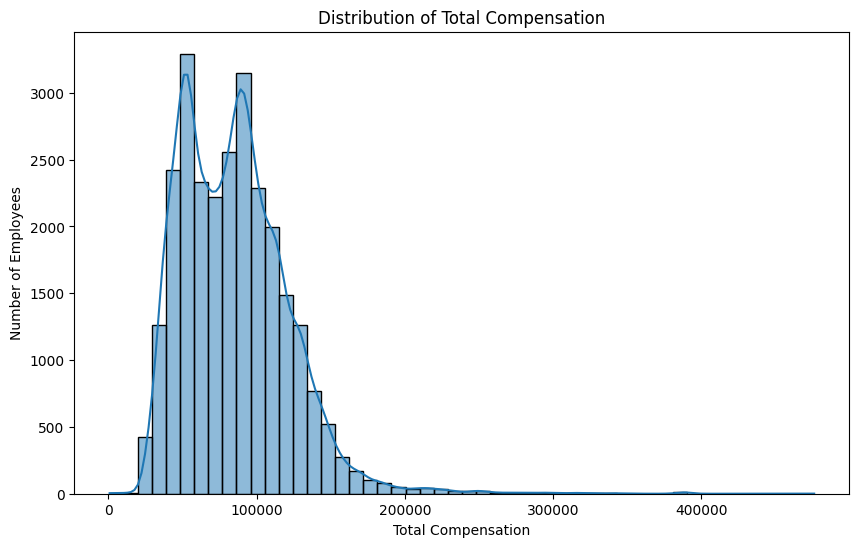

In [15]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="total_compensation",
    bins=50,
    kde=True
)

plt.title("Distribution of Total Compensation")
plt.xlabel("Total Compensation")
plt.ylabel("Number of Employees")
plt.show()

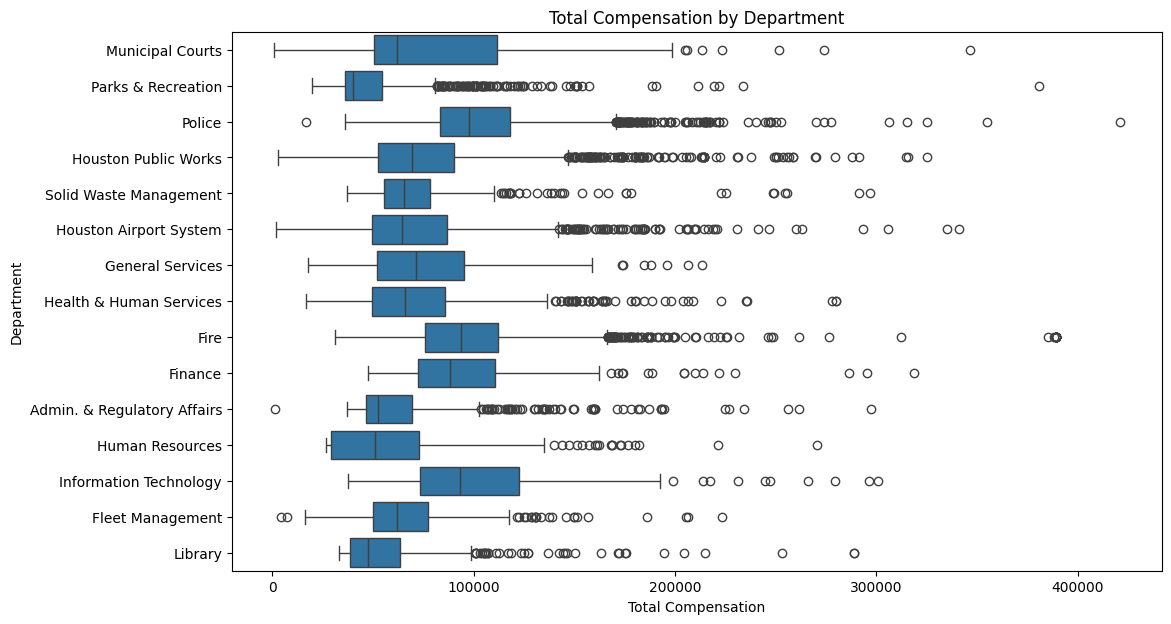

In [16]:
top_departments = (
    df["Department Name"]
    .value_counts()
    .head(15)
    .index
)

plot_df = df[df["Department Name"].isin(top_departments)]

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=plot_df,
    x="total_compensation",
    y="Department Name"
)

plt.title("Total Compensation by Department")
plt.xlabel("Total Compensation")
plt.ylabel("Department")
plt.show()

### Distribution of Numerical Compensation Columns

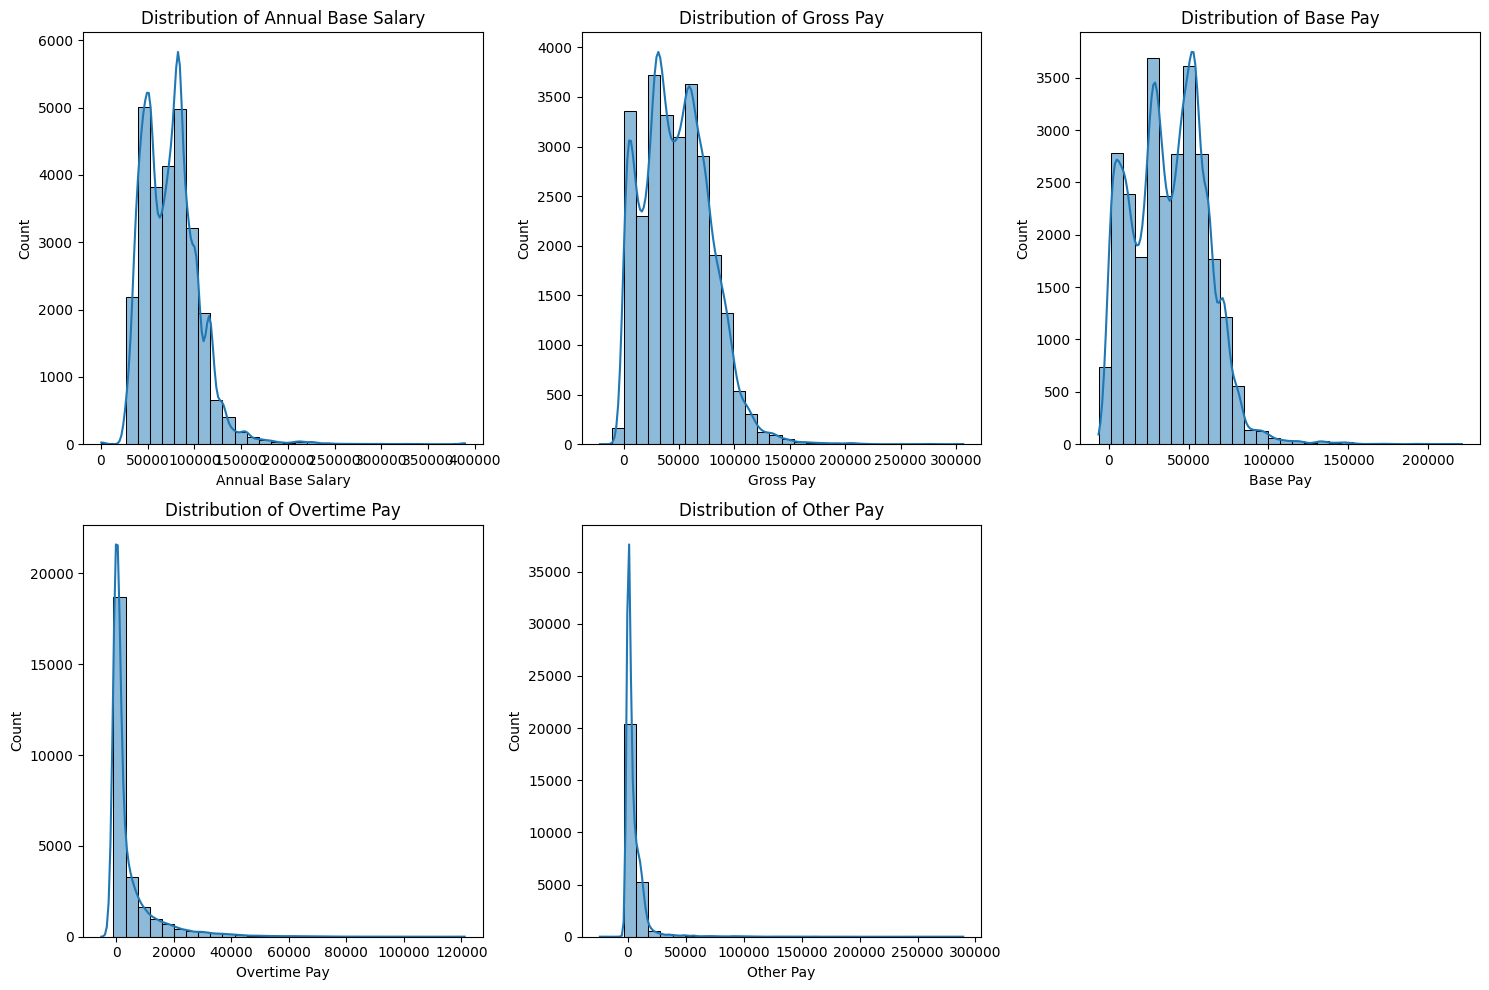

In [17]:
numerical_compensation_cols = [
    'Annual Base Salary', 'Gross Pay', 'Base Pay', 'Overtime Pay', 'Other Pay'
]

plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_compensation_cols):
    plt.subplot(2, 3, i + 1) # Arrange plots in 2 rows, 3 columns
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')

plt.tight_layout()
plt.show()

### Distribution of Birth Year

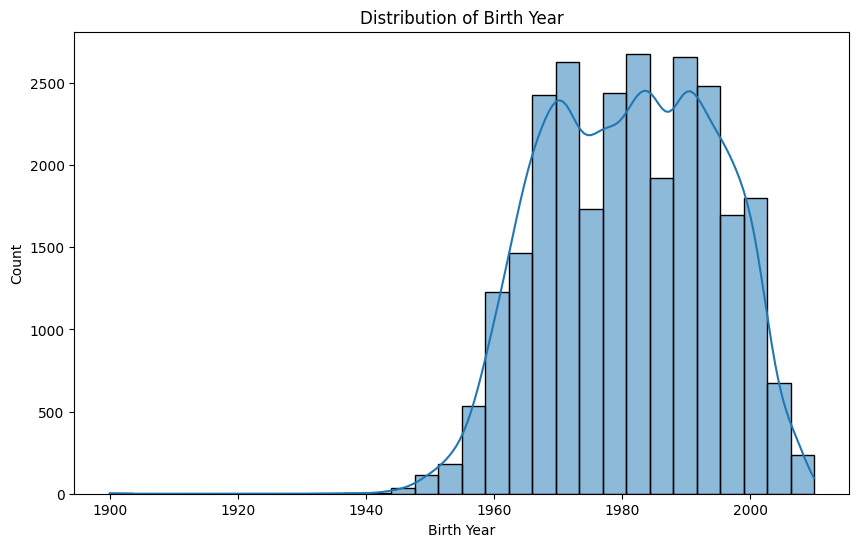

In [18]:
plt.figure(figsize=(10, 6))
sns.histplot(df['Birth Year'], kde=True, bins=30)
plt.title('Distribution of Birth Year')
plt.xlabel('Birth Year')
plt.ylabel('Count')
plt.show()

### Base Pay Distribution by Pay Grade

### Pay Grade Distribution by Department

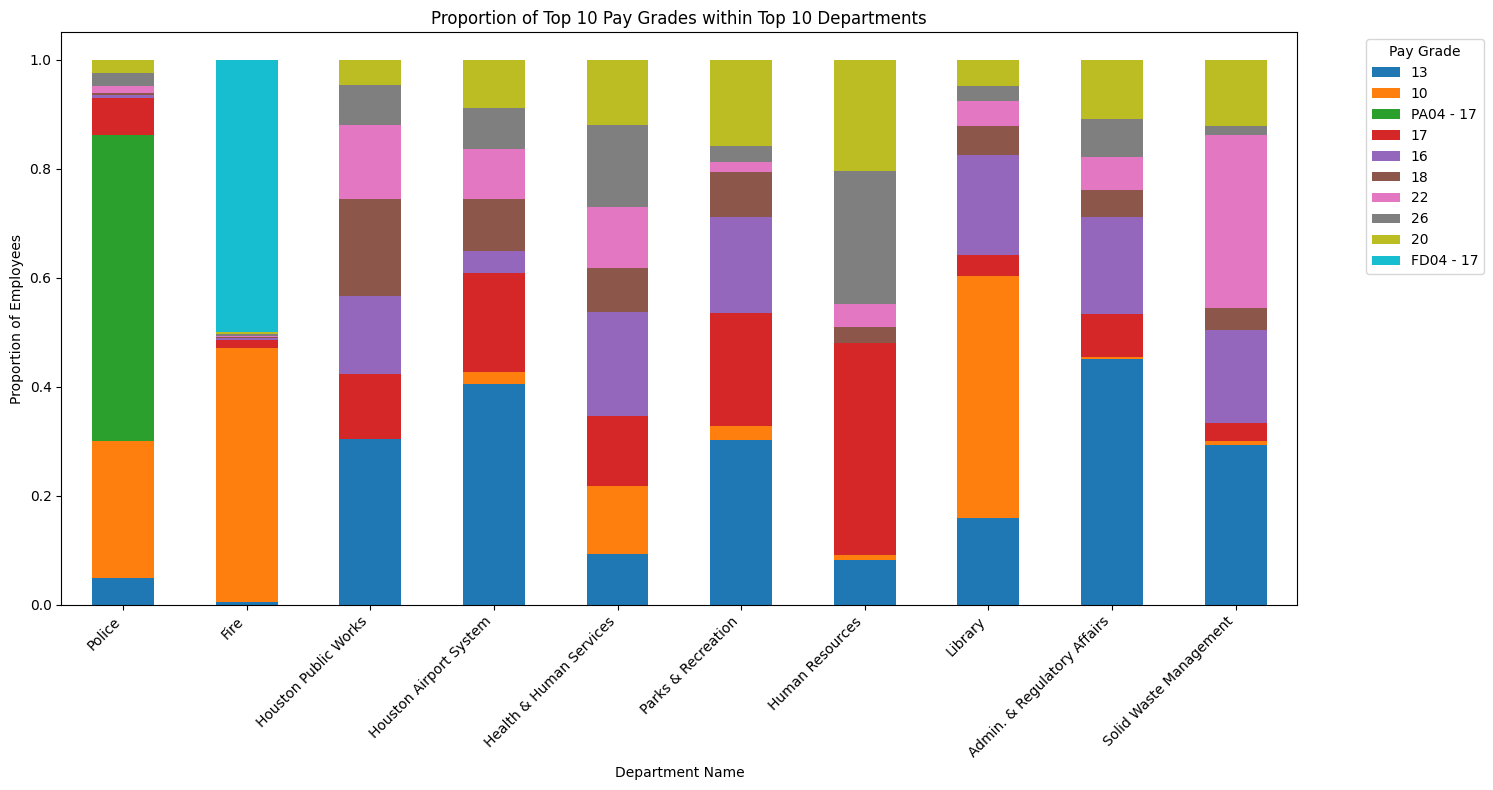

In [19]:
# Identify the top 10 departments by employee count
top_10_departments = df['Department Name'].value_counts().head(10).index.tolist()

# Identify the top 10 pay grades by overall employee count
top_10_pay_grades = df['Pay Grade'].value_counts().head(10).index.tolist()

# Filter the DataFrame to include only these top departments and top pay grades
filtered_df = df[
    df['Department Name'].isin(top_10_departments) &
    df['Pay Grade'].isin(top_10_pay_grades)
].copy()

# Create a cross-tabulation of Department Name and Pay Grade, showing proportions
pivot_table = filtered_df.groupby('Department Name')['Pay Grade'].value_counts(normalize=True).unstack(fill_value=0)

# Ensure consistent order for departments and pay grades in the plot
pivot_table = pivot_table.loc[top_10_departments] # Order departments
pivot_table = pivot_table[top_10_pay_grades] # Order pay grades

# Plot a stacked bar chart
pivot_table.plot(kind='bar', stacked=True, figsize=(15, 8))
plt.title('Proportion of Top 10 Pay Grades within Top 10 Departments')
plt.xlabel('Department Name')
plt.ylabel('Proportion of Employees')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Pay Grade', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Age Distribution by Department

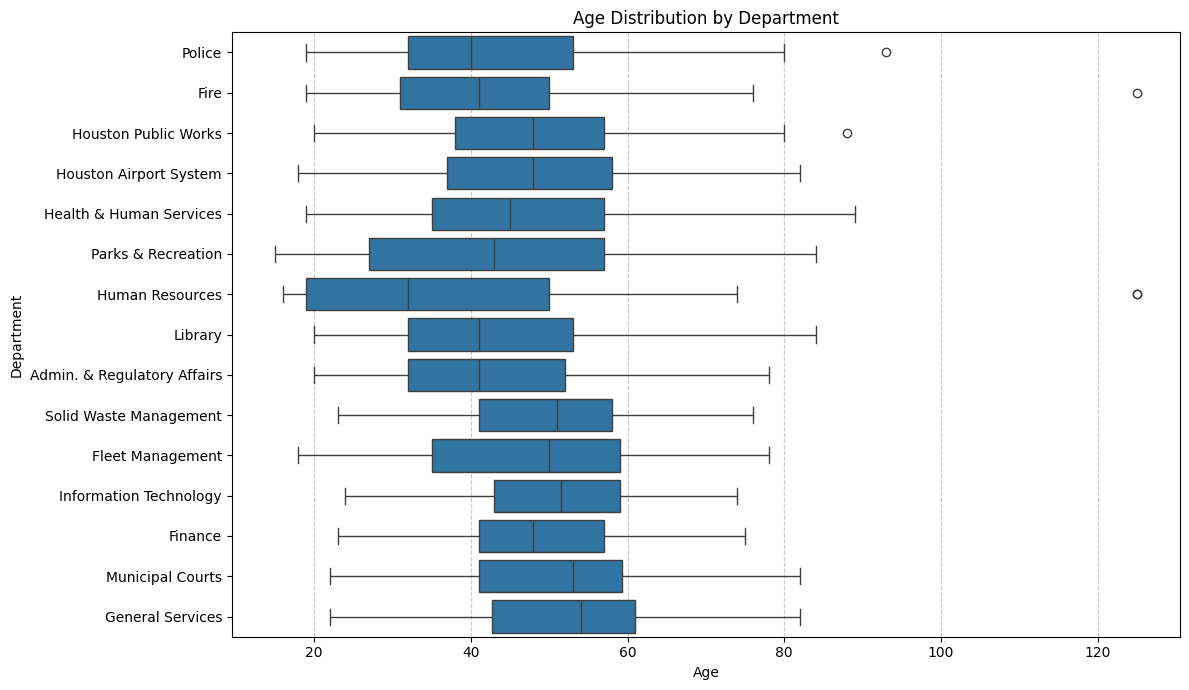

In [20]:
# Calculate 'Age' assuming the current year is 2025 (based on payroll-2025.csv)
df['Age'] = 2025 - df['Birth Year']

# Identify the top 15 departments by employee count (reusing previous logic for consistency)
top_departments_for_age = (
    df['Department Name']
    .value_counts()
    .head(15)
    .index
)

# Filter the DataFrame to include only these top departments
plot_df_age = df[df['Department Name'].isin(top_departments_for_age)]

plt.figure(figsize=(12, 7))
sns.boxplot(
    data=plot_df_age,
    x='Age',
    y='Department Name',
    order=top_departments_for_age # Ensure consistent ordering
)

plt.title('Age Distribution by Department')
plt.xlabel('Age')
plt.ylabel('Department')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Correlation between Age and Pay

In [21]:
print(f"Correlation between Age and Annual Base Salary: {df['Age'].corr(df['Annual Base Salary']):.2f}")
print(f"Correlation between Age and Total Compensation: {df['Age'].corr(df['total_compensation']):.2f}")

Correlation between Age and Annual Base Salary: 0.30
Correlation between Age and Total Compensation: 0.32


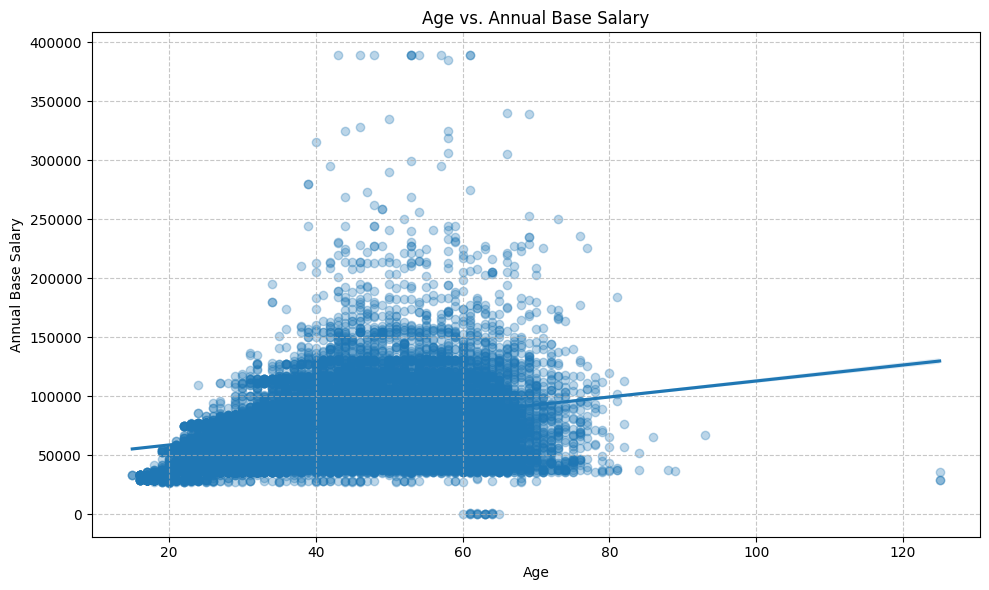

In [22]:
plt.figure(figsize=(10, 6))
sns.regplot(data=df, x='Age', y='Annual Base Salary', scatter_kws={'alpha':0.3})
plt.title('Age vs. Annual Base Salary')
plt.xlabel('Age')
plt.ylabel('Annual Base Salary')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

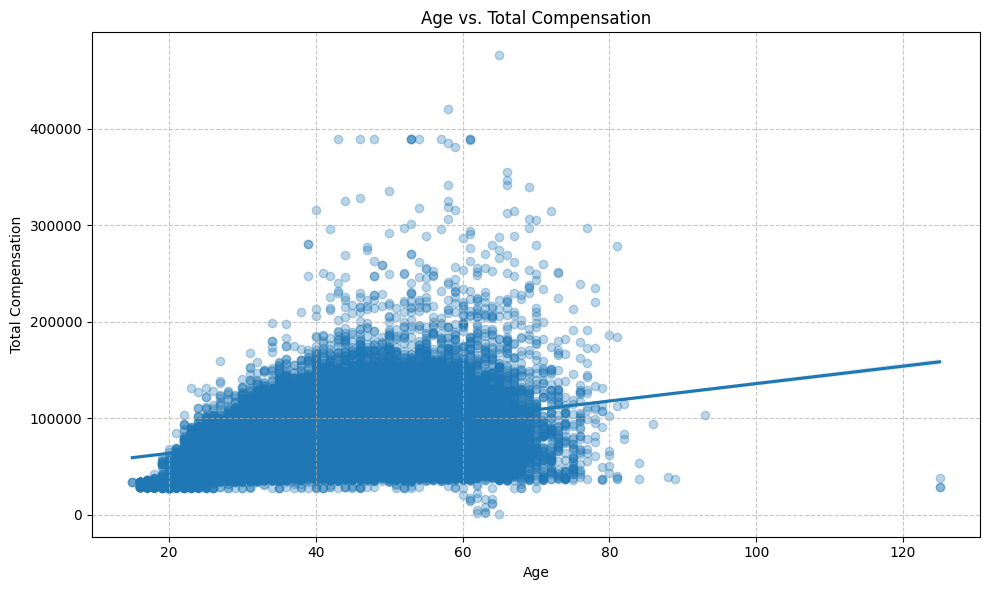

In [23]:
plt.figure(figsize=(10, 6))
sns.regplot(data=df, x='Age', y='total_compensation', scatter_kws={'alpha':0.3})
plt.title('Age vs. Total Compensation')
plt.xlabel('Age')
plt.ylabel('Total Compensation')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [24]:
df_capped = df[df['Annual Base Salary'] <= 150000].copy()
df_capped['Annual Base Salary'] = df_capped['Annual Base Salary'].apply(lambda x: min(x, 150000))
df_capped['total_compensation'] = (df_capped['Annual Base Salary'] + df_capped['Overtime Pay'] + df_capped['Other Pay']).apply(lambda x: min(x, 150000))

### Correlation between Age and Capped Pay

In [25]:
print(f"Correlation between Age and Capped Annual Base Salary: {df_capped['Age'].corr(df_capped['Annual Base Salary']):.2f}")
print(f"Correlation between Age and Capped Total Compensation: {df_capped['Age'].corr(df_capped['total_compensation']):.2f}")

Correlation between Age and Capped Annual Base Salary: 0.30
Correlation between Age and Capped Total Compensation: 0.32


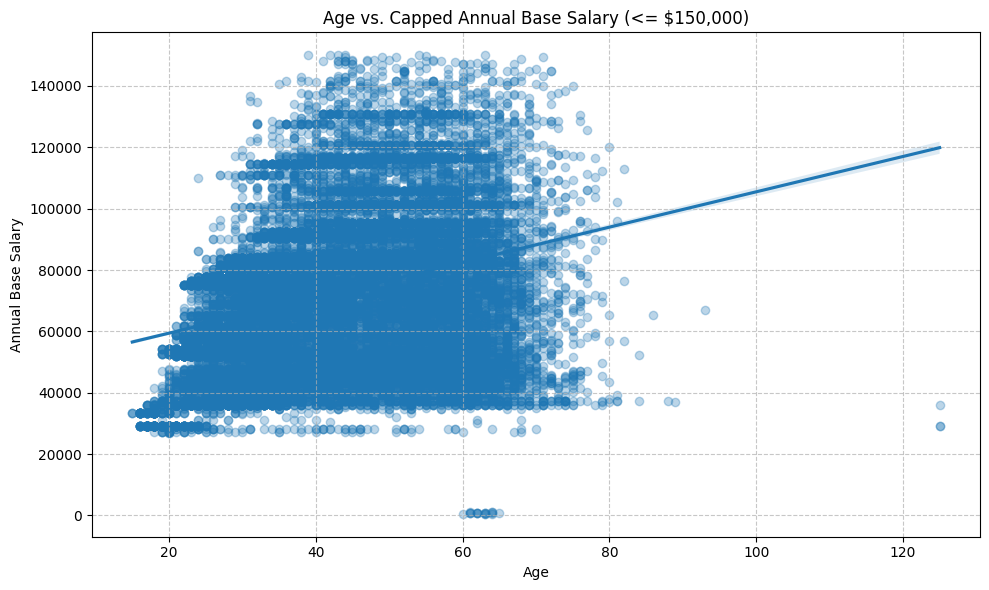

In [26]:
plt.figure(figsize=(10, 6))
sns.regplot(data=df_capped, x='Age', y='Annual Base Salary', scatter_kws={'alpha':0.3})
plt.title('Age vs. Capped Annual Base Salary (<= $150,000)')
plt.xlabel('Age')
plt.ylabel('Annual Base Salary')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

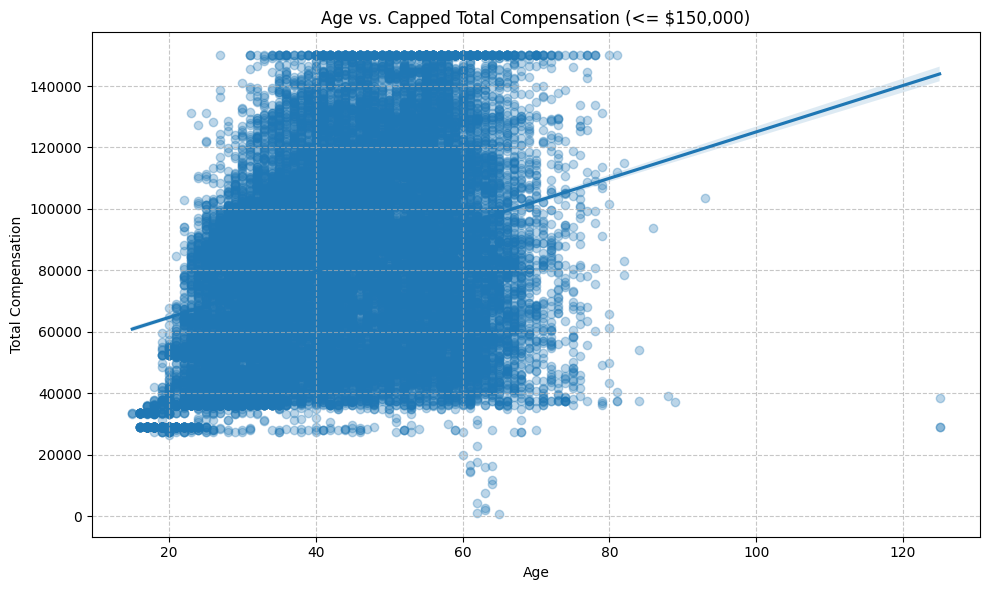

In [27]:
plt.figure(figsize=(10, 6))
sns.regplot(data=df_capped, x='Age', y='total_compensation', scatter_kws={'alpha':0.3})
plt.title('Age vs. Capped Total Compensation (<= $150,000)')
plt.xlabel('Age')
plt.ylabel('Total Compensation')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Correlation between Age and Pay with new capping limits

Let's apply the new capping limits for 'Annual Base Salary' at $100,000 and 'Age' at 65 to analyze their correlation.

In [28]:
# Create a new DataFrame with the specified capping limits
df_capped_new = df.copy()

# Cap 'Annual Base Salary' at $100,000
df_capped_new['Annual Base Salary'] = df_capped_new['Annual Base Salary'].apply(lambda x: min(x, 100000))

# Recalculate 'total_compensation' with the capped 'Annual Base Salary' and then cap it at $100,000
df_capped_new['total_compensation'] = (df_capped_new['Annual Base Salary'] + df_capped_new['Overtime Pay'] + df_capped_new['Other Pay']).apply(lambda x: min(x, 100000))

# Cap 'Age' at 65
df_capped_new['Age'] = df_capped_new['Age'].apply(lambda x: min(x, 65))

print("DataFrame with new capping limits created: df_capped_new")

DataFrame with new capping limits created: df_capped_new


In [29]:
print(f"Correlation between Capped Age (<=65) and Capped Annual Base Salary (<=100k): {df_capped_new['Age'].corr(df_capped_new['Annual Base Salary']):.2f}")
print(f"Correlation between Capped Age (<=65) and Capped Total Compensation (<=100k): {df_capped_new['Age'].corr(df_capped_new['total_compensation']):.2f}")

Correlation between Capped Age (<=65) and Capped Annual Base Salary (<=100k): 0.31
Correlation between Capped Age (<=65) and Capped Total Compensation (<=100k): 0.31


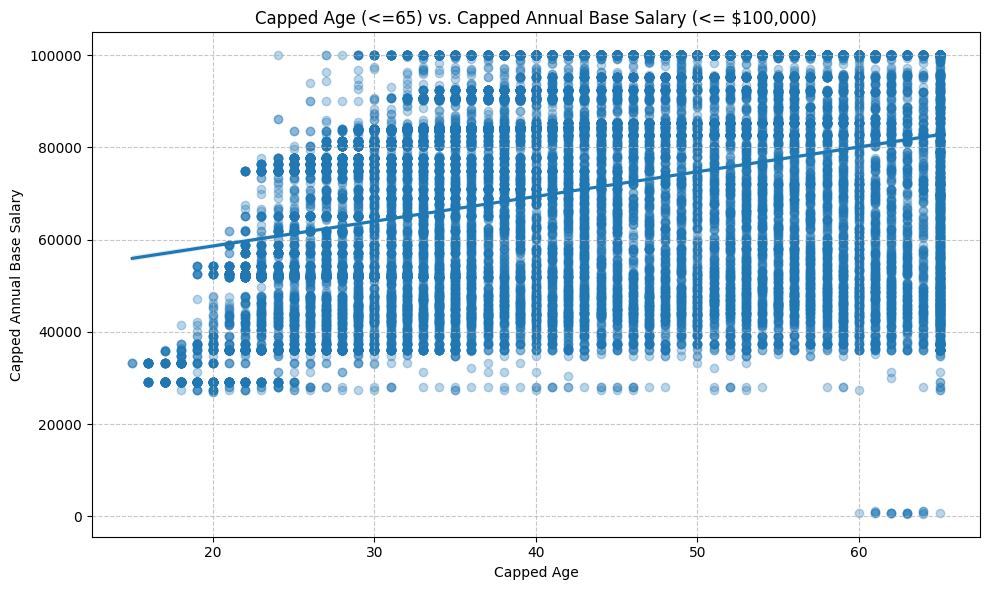

In [30]:
plt.figure(figsize=(10, 6))
sns.regplot(data=df_capped_new, x='Age', y='Annual Base Salary', scatter_kws={'alpha':0.3})
plt.title('Capped Age (<=65) vs. Capped Annual Base Salary (<= $100,000)')
plt.xlabel('Capped Age')
plt.ylabel('Capped Annual Base Salary')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

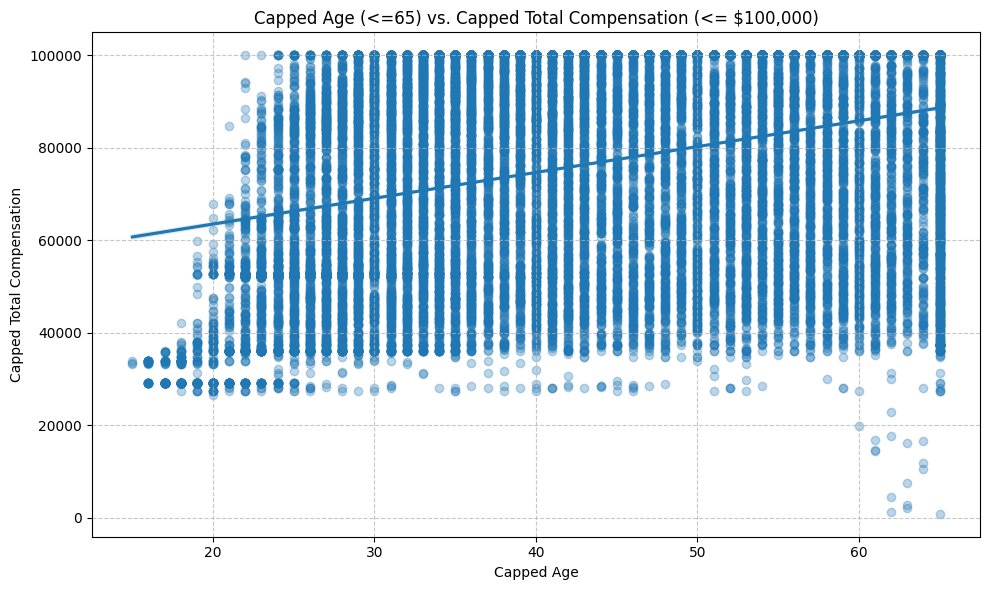

In [31]:
plt.figure(figsize=(10, 6))
sns.regplot(data=df_capped_new, x='Age', y='total_compensation', scatter_kws={'alpha':0.3})
plt.title('Capped Age (<=65) vs. Capped Total Compensation (<= $100,000)')
plt.xlabel('Capped Age')
plt.ylabel('Capped Total Compensation')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

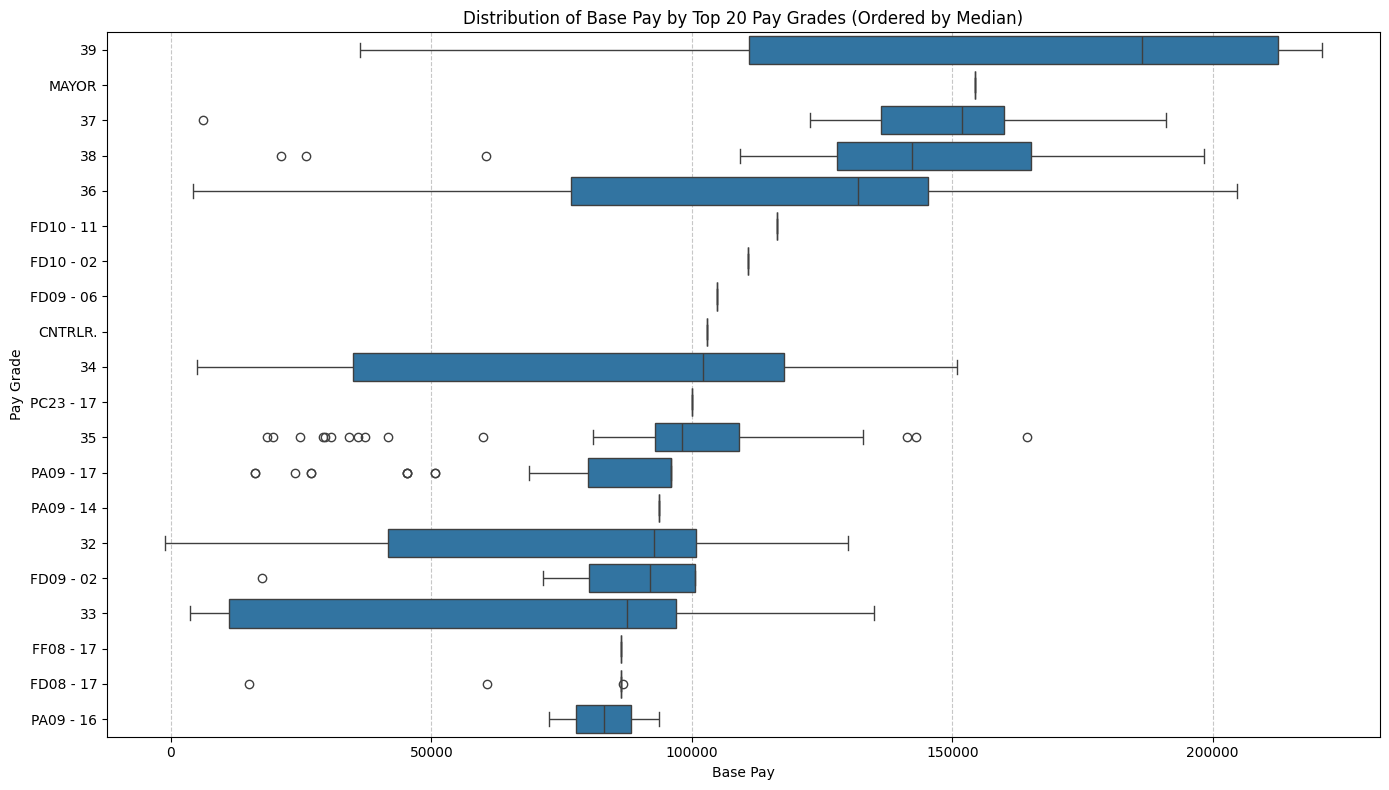

In [32]:
# Calculate median Base Pay for each Pay Grade to order the plot
pay_grade_order = df.groupby('Pay Grade')['Base Pay'].median().sort_values(ascending=False).index

# Select the top N pay grades to avoid cluttering the plot
n_top_pay_grades = 20
top_pay_grades = pay_grade_order[:n_top_pay_grades]

# Filter the DataFrame to include only the top pay grades
plot_df_pay_grade = df[df['Pay Grade'].isin(top_pay_grades)].copy()

plt.figure(figsize=(14, 8))
sns.boxplot(data=plot_df_pay_grade, x='Base Pay', y='Pay Grade', order=top_pay_grades)
plt.title('Distribution of Base Pay by Top 20 Pay Grades (Ordered by Median)')
plt.xlabel('Base Pay')
plt.ylabel('Pay Grade')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Unique Values in Object Columns

In [33]:
for column in df.select_dtypes(include='object').columns:
    print(f"Column '{column}':")
    print(df[column].value_counts())
    print("\n" + "="*50 + "\n")

Column 'Hash1':
Hash1
5A0974FFB6F9D21D67120C309379B0F04A027A9A    4
E7A4AE40D66B4A879A19C2AFC2B00271C140CBC9    3
259B0A0F72C1139EEC1592B341389E50863B0DCF    3
C43DA2D12CC448AEA364331AF19C2079A3C3A651    3
0FE52FB808BA5B78473CCCBBB32045DE9CF2789E    3
                                           ..
BA9CED0BC46B1BBA71986E7E9D941CF3025F4742    1
9CAB06C78EFFC8F44D44A5813E8C1F26CAF5479F    1
ED6FD553917E0EEEDABEE94B23C324EA243D9389    1
D673E739E440734032371657742DBAC91BF97579    1
A7BEE4D5B99A3E1DB759737A24C5709BBA19589B    1
Name: count, Length: 24396, dtype: int64


Column 'Hash2':
Hash2
8FBD6E88FE846F798156B53582A07FE68C24D5D8    1
4F2E3C274FFDC92F8436C9E15BF42DEDA1B62DEA    1
D9EFEE57EBA8157AAEBE1FC9B3EAEBD0348C7652    1
A4B01138B5CF79624949F94BDAE9366E6469F5E8    1
50FAA8C948DD01067D238331EABD3E888DFE1033    1
                                           ..
5B7934DFF62810A3C019B76B872B70F8D8B76A6A    1
17087950840DE60022A7D262372564767723AACE    1
87076E3C27D5969751458F369B00D643DB2A0DB

### Removing Identifier Columns

In [34]:
df = df.drop(columns=['Hash1', 'Hash2'])
print("Dropped 'Hash1' and 'Hash2' columns.")
display(df.head())

Dropped 'Hash1' and 'Hash2' columns.


,Birth Year,Gender,Race,Pay Grade,FLSA Status,EEOJ Code,Employment Type,Department ID,Department Name,Status,...,Date Position Ended,Annual Base Salary,Gross Pay,Base Pay,Overtime Pay,Other Pay,Simplified_Pay_Grade,total_compensation,overtime_ratio,Age
0,1955,Female,Black or African American,15,Non-Exempt,B: Professionals,Full Time,1600,Municipal Courts,Withdrawn,...,01/02/2025,51667.0,1286.61,1192.32,0.0,94.29,Grade_15,51761.29,0.000000,70
1,1955,Female,White,20,Exempt,B: Professionals,Full Time,3600,Parks & Recreation,Withdrawn,...,01/02/2025,67337.0,1890.61,1812.91,0.0,77.70,Grade_20,67414.70,0.000000,70
2,1963,Male,Black or African American,27,Exempt,B: Professionals,Full Time,1000,Police,Withdrawn,...,01/02/2025,117620.0,98009.09,3166.68,0.0,94842.41,Grade_27,212462.41,0.000000,62
3,1973,Male,Black or African American,06,Non-Exempt,H: Service/Maintenance,Full Time,2000,Houston Public Works,Withdrawn,...,01/02/2025,37794.0,2178.38,1090.20,290.3,797.88,Grade_6,38882.18,0.007681,52
4,1959,Male,Black or African American,13,Non-Exempt,H: Service/Maintenance,Full Time,2100,Solid Waste Management,Withdrawn,...,01/02/2025,58386.0,20728.21,1571.92,0.0,19156.29,Grade_13,77542.29,0.000000,66


In [35]:
# Re-initializing libraries and DataFrame to ensure all dependencies are met for subsequent operations
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("/content/drive/MyDrive/payroll-2025.csv")

# Drop identifier columns (as done in cell 4db35886)
df = df.drop(columns=['Hash1', 'Hash2'])

# Recalculate 'total_compensation' (as done in cell UtaDf1QKO1oG)
df["total_compensation"] = (
    df["Annual Base Salary"]
    + df["Overtime Pay"]
    + df["Other Pay"]
)

# Recalculate 'overtime_ratio' (as done in cell I8cznNRfPbb3)
df["overtime_ratio"] = (
    df["Overtime Pay"] / df["Annual Base Salary"]
)

# Recalculate 'Age' (as done in cell 165e104c)
df['Age'] = 2025 - df['Birth Year']

print("Libraries imported and DataFrame 'df' re-initialized with all previous preprocessing steps.")

display(df.head())

Libraries imported and DataFrame 'df' re-initialized with all previous preprocessing steps.


,Birth Year,Gender,Race,Pay Grade,FLSA Status,EEOJ Code,Employment Type,Department ID,Department Name,Status,...,Date Position Began,Date Position Ended,Annual Base Salary,Gross Pay,Base Pay,Overtime Pay,Other Pay,total_compensation,overtime_ratio,Age
0,1955,Female,Black or African American,15,Non-Exempt,B: Professionals,Full Time,1600,Municipal Courts,Withdrawn,...,01/01/2025,01/02/2025,51667.0,1286.61,1192.32,0.0,94.29,51761.29,0.000000,70
1,1955,Female,White,20,Exempt,B: Professionals,Full Time,3600,Parks & Recreation,Withdrawn,...,01/01/2025,01/02/2025,67337.0,1890.61,1812.91,0.0,77.70,67414.70,0.000000,70
2,1963,Male,Black or African American,27,Exempt,B: Professionals,Full Time,1000,Police,Withdrawn,...,01/01/2025,01/02/2025,117620.0,98009.09,3166.68,0.0,94842.41,212462.41,0.000000,62
3,1973,Male,Black or African American,06,Non-Exempt,H: Service/Maintenance,Full Time,2000,Houston Public Works,Withdrawn,...,01/01/2025,01/02/2025,37794.0,2178.38,1090.20,290.3,797.88,38882.18,0.007681,52
4,1959,Male,Black or African American,13,Non-Exempt,H: Service/Maintenance,Full Time,2100,Solid Waste Management,Withdrawn,...,01/01/2025,01/02/2025,58386.0,20728.21,1571.92,0.0,19156.29,77542.29,0.000000,66


### Correlation between Years Since Position Began and Pay

To analyze this, we'll convert `Date Position Began` into a numerical feature representing the years since the position began.

In [36]:
# Convert 'Date Position Began' to datetime objects if not already done
df['Date Position Began'] = pd.to_datetime(df['Date Position Began'])

# Assuming the data is for 2025, calculate 'Years Since Position Began'
current_year = 2025
df['Years Since Position Began'] = current_year - df['Date Position Began'].dt.year

print("Calculated 'Years Since Position Began' feature.")
display(df[['Date Position Began', 'Years Since Position Began', 'Annual Base Salary', 'total_compensation']].head())

Calculated 'Years Since Position Began' feature.


,Date Position Began,Years Since Position Began,Annual Base Salary,total_compensation
0,2025-01-01,0,51667.0,51761.29
1,2025-01-01,0,67337.0,67414.70
2,2025-01-01,0,117620.0,212462.41
3,2025-01-01,0,37794.0,38882.18
4,2025-01-01,0,58386.0,77542.29


In [37]:
print(f"Correlation between Years Since Position Began and Annual Base Salary: {df['Years Since Position Began'].corr(df['Annual Base Salary']):.2f}")
print(f"Correlation between Years Since Position Began and Total Compensation: {df['Years Since Position Began'].corr(df['total_compensation']):.2f}")

Correlation between Years Since Position Began and Annual Base Salary: 0.06
Correlation between Years Since Position Began and Total Compensation: 0.03


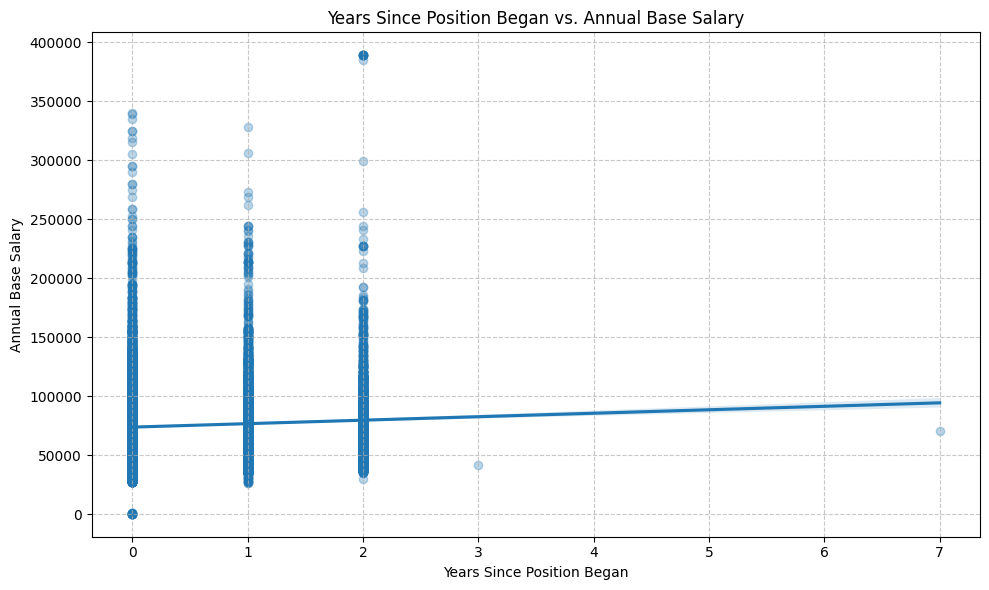

In [38]:
plt.figure(figsize=(10, 6))
sns.regplot(data=df, x='Years Since Position Began', y='Annual Base Salary', scatter_kws={'alpha':0.3})
plt.title('Years Since Position Began vs. Annual Base Salary')
plt.xlabel('Years Since Position Began')
plt.ylabel('Annual Base Salary')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

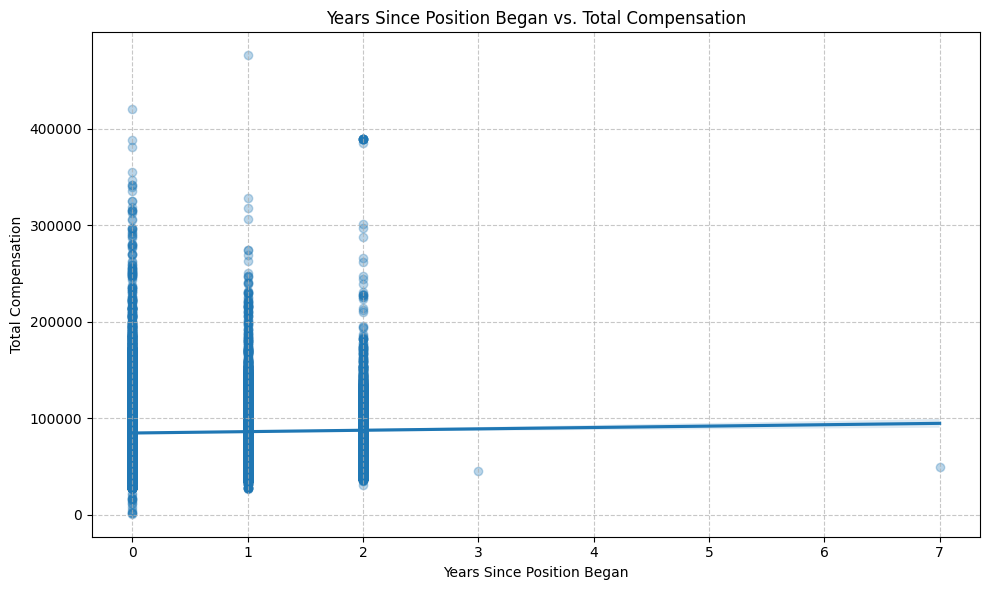

In [39]:
plt.figure(figsize=(10, 6))
sns.regplot(data=df, x='Years Since Position Began', y='total_compensation', scatter_kws={'alpha':0.3})
plt.title('Years Since Position Began vs. Total Compensation')
plt.xlabel('Years Since Position Began')
plt.ylabel('Total Compensation')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [40]:
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(
    df["Department Name"],
    df["Pay Grade"]
)

chi2, p_value, degrees_of_freedom, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("p-value:", p_value)
print("Degrees of freedom:", degrees_of_freedom)

Chi-square statistic: 98504.61411356251
p-value: 0.0
Degrees of freedom: 5208


In [41]:
import statsmodels.api as sm # Import statsmodels.api for direct OLS
import statsmodels.formula.api as smf

# Manually create dummy variables for 'Pay Grade' and 'Department Name'
df_model = df.copy()
df_model = pd.get_dummies(df_model, columns=['Pay Grade', 'Department Name'], drop_first=True)

# Define the dependent variable
y = df_model['Annual Base Salary']

# Define the independent variables (dummy variables for Pay Grade and Department Name)
independent_vars = [col for col in df_model.columns if col.startswith('Pay Grade_') or col.startswith('Department Name_')]
X = df_model[independent_vars]

# Add a constant (intercept) to the independent variables
X = sm.add_constant(X)

# Perform linear regression with 'Annual Base Salary' as the dependent variable
model_salary_factors = sm.OLS(y, X).fit()

print(model_salary_factors.summary())

                            OLS Regression Results                            
Dep. Variable:     Annual Base Salary   R-squared:                       0.941
Model:                            OLS   Adj. R-squared:                  0.940
Method:                 Least Squares   F-statistic:                     1755.
Date:                Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                        20:23:51   Log-Likelihood:            -2.7774e+05
No. Observations:               26928   AIC:                         5.560e+05
Df Residuals:                   26686   BIC:                         5.580e+05
Df Model:                         241                                         
Covariance Type:            nonrobust                                         
                                                    coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------

### Multiple Linear Regression with Additional Factors

Let's expand on the previous OLS regression by including additional factors such as `Gender`, `Race`, `Age`, and `Years Since Position Began` to predict `Annual Base Salary`. This will provide a more comprehensive view of how these variables collectively influence an employee's base salary.

In [42]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Prepare the DataFrame for regression by creating dummy variables for categorical features
# We'll include 'Gender', 'Race', 'FLSA Status', 'Employment Type', 'EEOJ Code', 'Pay Grade', and 'Department Name'
# 'Age' and 'Years Since Position Began' are already numerical.

df_regression = df.copy()

categorical_cols = [
    'Gender', 'Race', 'FLSA Status', 'EEOJ Code', 'Employment Type', 'Pay Grade', 'Department Name'
]

df_regression = pd.get_dummies(df_regression, columns=categorical_cols, drop_first=True)

# Define the dependent variable
y = df_regression['Annual Base Salary']

# Define the independent variables
# We will use 'Age', 'Years Since Position Began', and all the newly created dummy variables
independent_vars_full = [
    'Age', 'Years Since Position Began'
] + [col for col in df_regression.columns if any(col.startswith(cat + '_') for cat in categorical_cols)]

X_full = df_regression[independent_vars_full]

# Add a constant (intercept) to the independent variables
X_full = sm.add_constant(X_full)

# Perform linear regression
model_full_factors = sm.OLS(y, X_full).fit()

print(model_full_factors.summary())

                            OLS Regression Results                            
Dep. Variable:     Annual Base Salary   R-squared:                       0.942
Model:                            OLS   Adj. R-squared:                  0.941
Method:                 Least Squares   F-statistic:                     1643.
Date:                Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                        20:23:53   Log-Likelihood:            -2.7746e+05
No. Observations:               26928   AIC:                         5.555e+05
Df Residuals:                   26664   BIC:                         5.576e+05
Df Model:                         263                                         
Covariance Type:            nonrobust                                         
                                                     coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------

### Logistic Regression: Predicting High vs. Low Salaries by Department

Let's perform a logistic regression to understand how 'Department Name' influences the probability of an employee having a 'High Salary'. We'll define 'High Salary' as an 'Annual Base Salary' of $64,000 or more.

In [43]:
import statsmodels.api as sm

# Create the binary target variable 'High_Salary'
# 1 if Annual Base Salary >= $64,000, 0 otherwise
df['High_Salary'] = (df['Annual Base Salary'] >= 64000).astype(int)

# Prepare the independent variable: 'Department Name' as dummy variables
X_logistic = pd.get_dummies(df['Department Name'], drop_first=True)

# Add a constant (intercept) to the independent variables
X_logistic = sm.add_constant(X_logistic)

# Define the dependent variable
y_logistic = df['High_Salary']

# Perform Logistic Regression
logit_model = sm.Logit(y_logistic, X_logistic)
result = logit_model.fit()

print(result.summary())

Optimization terminated successfully.
         Current function value: 0.560027
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:            High_Salary   No. Observations:                26928
Model:                          Logit   Df Residuals:                    26903
Method:                           MLE   Df Model:                           24
Date:                Tue, 10 Nov 2026   Pseudo R-squ.:                  0.1636
Time:                        20:23:54   Log-Likelihood:                -15080.
converged:                       True   LL-Null:                       -18030.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const                            -1.0538      0.099    -10.622      0.

### Logistic Regression: Predicting High vs. Low Salaries by Age Group

Let's categorize the 'Age' into groups and then perform a logistic regression to see how different age groups influence the probability of an employee having a 'High Salary'.

In [44]:
import statsmodels.api as sm

# Define age bins and labels
age_bins = [0, 25, 35, 45, 55, 65, 150] # Assuming max age is around 150 for safety
age_labels = ['<25', '25-34', '35-44', '45-54', '55-64', '65+']

# Create a new 'Age_Group' column
df['Age_Group'] = pd.cut(df['Age'], bins=age_bins, labels=age_labels, right=False)

# Prepare the independent variable: 'Age_Group' as dummy variables
X_logistic_age_group = pd.get_dummies(df['Age_Group'], drop_first=True)

# Add a constant (intercept) to the independent variables
X_logistic_age_group = sm.add_constant(X_logistic_age_group)

# Define the dependent variable (High_Salary is already created)
y_logistic_age_group = df['High_Salary']

# Perform Logistic Regression
logit_model_age_group = sm.Logit(y_logistic_age_group, X_logistic_age_group)
result_age_group = logit_model_age_group.fit()

print(result_age_group.summary())

Optimization terminated successfully.
         Current function value: 0.612065
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:            High_Salary   No. Observations:                26928
Model:                          Logit   Df Residuals:                    26922
Method:                           MLE   Df Model:                            5
Date:                Tue, 10 Nov 2026   Pseudo R-squ.:                 0.08587
Time:                        20:23:54   Log-Likelihood:                -16482.
converged:                       True   LL-Null:                       -18030.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -2.3341      0.086    -27.295      0.000      -2.502      -2.166
25-34          2.2713      0.

### Logistic Regression with L1 (Lasso) Regularization

Let's apply L1 regularization to our logistic regression model. This technique helps in feature selection by shrinking the coefficients of less important features to zero, thus simplifying the model and reducing overfitting.

We will use `Age_Group`, `Department Name`, `Gender`, `Race`, `FLSA Status`, `EEOJ Code`, `Employment Type`, `Pay Grade`, and `Years Since Position Began` as predictors for `High_Salary`.

In [45]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# Define the target variable
y = df['High_Salary']

# Define the independent variables (features)
categorical_features = [
    'Age_Group', 'Department Name', 'Gender', 'Race', 'FLSA Status',
    'EEOJ Code', 'Employment Type', 'Pay Grade'
]
numerical_features = ['Years Since Position Began']

# Create a copy of the DataFrame for feature engineering
df_features = df[categorical_features + numerical_features].copy()

# One-hot encode categorical features
X = pd.get_dummies(df_features, columns=categorical_features, drop_first=True)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize and train the Logistic Regression model with L1 penalty
# C is the inverse of regularization strength; smaller values specify stronger regularization.
# solver='liblinear' or 'saga' are suitable for L1 penalty.
# max_iter is increased for convergence with potentially many features.
lasso_logistic_model = LogisticRegression(
    penalty='l1',
    solver='liblinear',
    C=0.1,
    random_state=42,
    max_iter=1000
)
lasso_logistic_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = lasso_logistic_model.predict(X_test)

# Evaluate the model
print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

print("\nCoefficients (Non-zero only):")
# Display coefficients, filtering out those that were shrunk to zero by L1 regularization
feature_names = X.columns
coefficients = lasso_logistic_model.coef_[0]

for name, coef in zip(feature_names, coefficients):
    if coef != 0:
        print(f"{name}: {coef:.4f}")


Accuracy: 0.9647233568510954

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.95      0.95      3156
           1       0.97      0.98      0.97      4923

    accuracy                           0.96      8079
   macro avg       0.96      0.96      0.96      8079
weighted avg       0.96      0.96      0.96      8079


Coefficients (Non-zero only):
Years Since Position Began: 0.0192
Age_Group_35-44: 0.5152
Age_Group_45-54: 0.8395
Age_Group_55-64: 0.6840
Age_Group_65+: 0.6762
Department Name_Department of Neighborhoods: -0.1676
Department Name_Fire: 1.4041
Department Name_Fleet Management: -1.8656
Department Name_Houston Emergency Center: 0.1410
Department Name_Houston Public Works: 0.1887
Department Name_Human Resources: -0.6700
Department Name_Information Technology: 0.4128
Department Name_Legal: 0.3572
Department Name_Library: -1.5196
Department Name_Municipal Courts: 0.0052
Department Name_Parks & Recreation: -1.1094
Depa

### Applying PCA for Dimension Reduction on Compensation Columns

In [46]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

# Select the key numerical compensation columns
comp_cols = ['Annual Base Salary', 'Gross Pay', 'Base Pay', 'Overtime Pay', 'Other Pay']
comp_data = df[comp_cols]

# Standardize the features before PCA
scaler = StandardScaler()
comp_scaled = scaler.fit_transform(comp_data)

# Fit PCA
pca = PCA(n_components=2)
pca_features = pca.fit_transform(comp_scaled)

# Calculate explained variance
explained_variance = pca.explained_variance_ratio_
print(f"Explained Variance by Component 1: {explained_variance[0]:.2%}")
print(f"Explained Variance by Component 2: {explained_variance[1]:.2%}")
print(f"Total Explained Variance (2 Components): {sum(explained_variance):.2%}")

# Examine factor loadings to understand what each component represents
loadings = pd.DataFrame(
    pca.components_.T,
    columns=['PC1 (Overall Pay Factor)', 'PC2 (Overtime/Other Pay Factor)'],
    index=comp_cols
)
display(loadings)

Explained Variance by Component 1: 55.42%
Explained Variance by Component 2: 19.87%
Total Explained Variance (2 Components): 75.29%


,PC1 (Overall Pay Factor),PC2 (Overtime/Other Pay Factor)
Annual Base Salary,0.490508,0.004028
Gross Pay,0.587425,0.044755
Base Pay,0.535425,-0.263448
Overtime Pay,0.280278,-0.316999
Other Pay,0.221583,0.909993


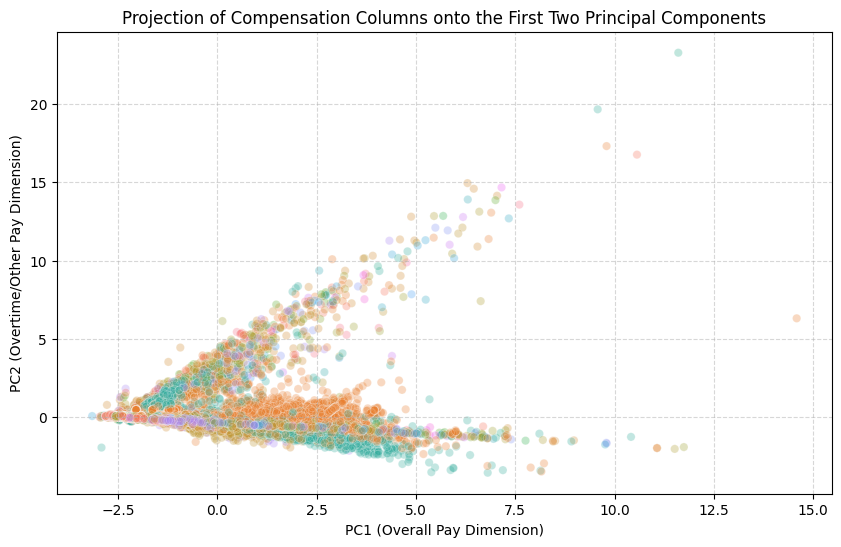

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize the principal components
df_pca = pd.DataFrame(pca_features, columns=['PC1', 'PC2'])
df_pca['Department'] = df['Department Name']

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='Department', alpha=0.3, legend=False)
plt.title('Projection of Compensation Columns onto the First Two Principal Components')
plt.xlabel('PC1 (Overall Pay Dimension)')
plt.ylabel('PC2 (Overtime/Other Pay Dimension)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Multiple Linear Regression using PCA-Reduced Compensation and Demographics

To resolve the multi-collinearity of our compensation metrics while retaining their core information, we utilize **PC1** and **PC2** as independent variables alongside **Age**, **Years Since Position Began**, **Gender**, and **Race** to model **total_compensation**.

In [48]:
import statsmodels.api as sm
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Let's use PCA correctly on numeric predictors to avoid multicollinearity among predictors,
# keeping the target ('total_compensation') completely independent of the PCA process.

# Standardize numeric predictors: 'Age' and 'Years Since Position Began'
predictor_cols = ['Age', 'Years Since Position Began']
scaler_preds = StandardScaler()
scaled_predictors = scaler_preds.fit_transform(df[predictor_cols])

# Apply PCA on these numeric predictors
pca_preds = PCA(n_components=2)
pca_pred_features = pca_preds.fit_transform(scaled_predictors)

# Create a copy of the dataframe for regression
df_pca_reg = df.copy()
df_pca_reg['PC1_Demographics'] = pca_pred_features[:, 0]
df_pca_reg['PC2_Demographics'] = pca_pred_features[:, 1]

# Select independent variables: PC features + categorical demographics
categorical_features = ['Gender', 'Race']

# Prepare the feature matrix by one-hot encoding categorical variables
X_pca_reg = df_pca_reg[categorical_features + ['PC1_Demographics', 'PC2_Demographics']].copy()
X_pca_reg = pd.get_dummies(X_pca_reg, columns=categorical_features, drop_first=True)

# Define the dependent variable (target is completely separate from PCA inputs)
y_pca_reg = df_pca_reg['total_compensation']

# Add constant intercept
X_pca_reg = sm.add_constant(X_pca_reg)

# Fit the OLS Model
model_pca_full = sm.OLS(y_pca_reg, X_pca_reg.astype(float)).fit()

print(model_pca_full.summary())

                            OLS Regression Results                            
Dep. Variable:     total_compensation   R-squared:                       0.188
Model:                            OLS   Adj. R-squared:                  0.188
Method:                 Least Squares   F-statistic:                     567.1
Date:                Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                        20:23:56   Log-Likelihood:            -3.1828e+05
No. Observations:               26928   AIC:                         6.366e+05
Df Residuals:                   26916   BIC:                         6.367e+05
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                                                     coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------

In [49]:
import statsmodels.api as sm
import pandas as pd

# Prepare simplified pay grade variables if not already fully applied to df
if 'Simplified_Pay_Grade' not in df.columns:
    df['Simplified_Pay_Grade'] = df['Pay Grade'].apply(simplify_pay_grade)

# Create a copy for the robust model
df_robust_model = df.copy()

# Incorporate the demographic PCA components we calculated earlier
df_robust_model['PC1_Demographics'] = pca_pred_features[:, 0]
df_robust_model['PC2_Demographics'] = pca_pred_features[:, 1]

# Variables to include: PC Demographics + Categorical Demographics + Job Factors
categorical_controls = ['Gender', 'Race', 'Simplified_Pay_Grade', 'Department Name']

# Create dummy variables
X_robust = df_robust_model[categorical_controls + ['PC1_Demographics', 'PC2_Demographics']].copy()
X_robust = pd.get_dummies(X_robust, columns=categorical_controls, drop_first=True)

# Target Variable
y_robust = df_robust_model['total_compensation']

# Add constant intercept
X_robust = sm.add_constant(X_robust)

# Fit the robust model
model_robust = sm.OLS(y_robust, X_robust.astype(float)).fit()

# Print the R-squared and select coefficients of interest (demographics)
print(f"Robust Model R-squared (Total Explained Variance): {model_robust.rsquared:.4f}")
print(f"Robust Model Adjusted R-squared: {model_robust.rsquared_adj:.4f}\n")

# Isolate and display demographic coefficients to check for pay gaps
coefficients_df = model_robust.params.to_frame('Coefficient')
pvalues_df = model_robust.pvalues.to_frame('p-value')
summary_demographics = coefficients_df.join(pvalues_df).filter(regex='Gender_|Race_|PC[12]_Demographics', axis=0)

display(summary_demographics)

Robust Model R-squared (Total Explained Variance): 0.7141
Robust Model Adjusted R-squared: 0.7133



,Coefficient,p-value
PC1_Demographics,3538.654203,8.184000e-160
PC2_Demographics,4914.590109,5.631330e-252
Gender_Male,4635.541942,4.041931e-56
Race_Asian,262.475354,8.885864e-01
Race_Asian/Pacific Islander,-10935.180136,3.611872e-02
Race_Black or African American,-3180.035855,8.228685e-02
Race_Hispanic/Latino,-543.841587,7.665190e-01
Race_Native Hawaiian or Other Pacific Islander,-106.394188,9.741726e-01
Race_Others,303.763232,9.209773e-01
Race_Two or More Races,-4081.364251,2.086487e-01


In [50]:
import numpy as np
import statsmodels.api as sm
import pandas as pd

# Create log-transformed target variable
# We use log1p to handle any potential 0 or negative values safely (though compensation should be positive)
df['log_total_compensation'] = np.log1p(df['total_compensation'])

# Prepare the DataFrame
df_log_model = df.copy()
df_log_model['PC1_Demographics'] = pca_pred_features[:, 0]
df_log_model['PC2_Demographics'] = pca_pred_features[:, 1]

categorical_controls = ['Gender', 'Race', 'Simplified_Pay_Grade', 'Department Name']

# Create dummy variables
X_log = df_log_model[categorical_controls + ['PC1_Demographics', 'PC2_Demographics']].copy()
X_log = pd.get_dummies(X_log, columns=categorical_controls, drop_first=True)

# Define the log-transformed dependent variable
y_log = df_log_model['log_total_compensation']

# Add constant intercept
X_log = sm.add_constant(X_log)

# Fit the OLS Model
model_log_robust = sm.OLS(y_log, X_log.astype(float)).fit()

print(f"Log-Transformed Model R-squared: {model_log_robust.rsquared:.4f}")
print(f"Log-Transformed Model Adjusted R-squared: {model_log_robust.rsquared_adj:.4f}")


Log-Transformed Model R-squared: 0.7330
Log-Transformed Model Adjusted R-squared: 0.7323


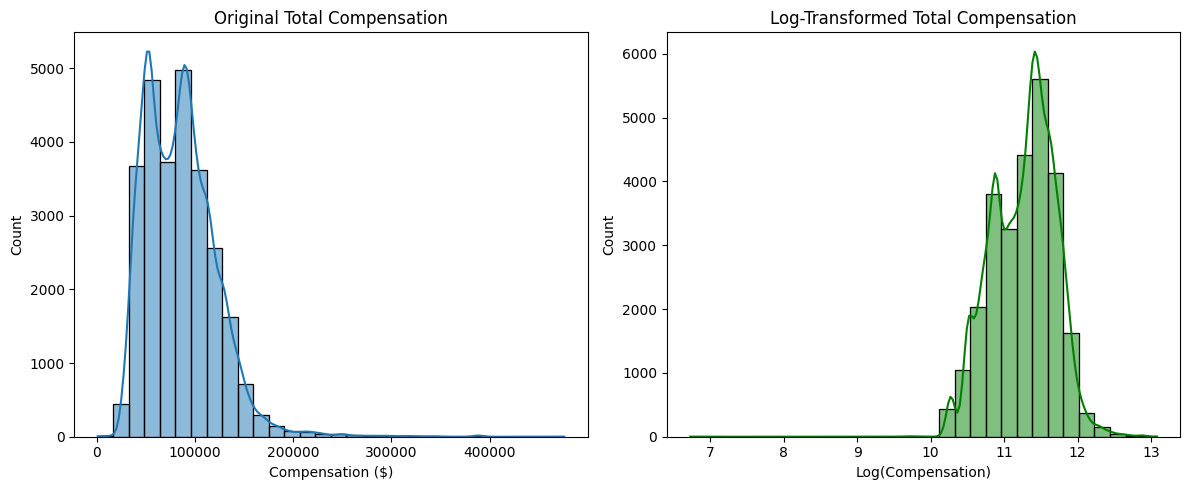

In [51]:
# Compare the summary statistics of the log-transformed model residuals
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

# Subplot 1: Distribution of Total Compensation
plt.subplot(1, 2, 1)
sns.histplot(df['total_compensation'], kde=True, bins=30)
plt.title('Original Total Compensation')
plt.xlabel('Compensation ($)')

# Subplot 2: Distribution of Log Total Compensation
plt.subplot(1, 2, 2)
sns.histplot(df['log_total_compensation'], kde=True, bins=30, color='green')
plt.title('Log-Transformed Total Compensation')
plt.xlabel('Log(Compensation)')

plt.tight_layout()
plt.show()


In [52]:
import numpy as np
import pandas as pd

# Isolate the coefficients and p-values for demographic variables from our log-transformed model
log_coefficients = model_log_robust.params.to_frame('Coefficient')
log_pvalues = model_log_robust.pvalues.to_frame('p-value')

# Join metrics and filter to select gender, race, and age/demographic PCA dimensions
demographic_gaps = log_coefficients.join(log_pvalues).filter(regex='Gender_|Race_|PC[12]_Demographics', axis=0)

# Calculate the exact percentage difference: (e^coef - 1) * 100
demographic_gaps['Percentage Pay Impact (%)'] = (np.exp(demographic_gaps['Coefficient']) - 1) * 100

# Sort by pay impact to identify the largest gaps
demographic_gaps = demographic_gaps.sort_values(by='Percentage Pay Impact (%)', ascending=False)

# Format output for presentation
demographic_gaps['Significant?'] = demographic_gaps['p-value'].apply(lambda x: 'Yes' if x < 0.05 else 'No')
display(demographic_gaps.style.format({
    'Coefficient': '{:.4f}',
    'p-value': '{:.4e}',
    'Percentage Pay Impact (%)': '{:+.2f}%'
}))

,Coefficient,p-value,Percentage Pay Impact (%),Significant?
Gender_Male,0.0628,4.3324e-79,+6.48%,Yes
PC2_Demographics,0.0575,5.8264e-268,+5.92%,Yes
PC1_Demographics,0.0420,7.6729e-175,+4.29%,Yes
Race_Native Hawaiian or Other Pacific Islander,0.0127,7.3267e-01,+1.28%,No
Race_Asian,0.0018,9.3137e-01,+0.18%,No
Race_Hispanic/Latino,-0.0033,8.7561e-01,-0.32%,No
Race_White,-0.0047,8.2190e-01,-0.47%,No
Race_Others,-0.0065,8.5052e-01,-0.65%,No
Race_Black or African American,-0.0425,4.0782e-02,-4.16%,Yes
Race_Two or More Races,-0.0502,1.7269e-01,-4.90%,No


### Evaluating a Random Forest Regressor
Let's build a Random Forest Regressor to predict `Annual Base Salary` using our demographic and organizational features, and compare its performance with our previous linear models.

In [53]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import pandas as pd
import numpy as np

# Prepare features (using the same categorical features from our earlier models)
features_df = df[[
    'Age', 'Years Since Position Began', 'Gender', 'Race',
    'FLSA Status', 'EEOJ Code', 'Employment Type', 'Department Name'
]].copy()

# One-hot encode categorical features
X_rf = pd.get_dummies(features_df, drop_first=True)
y_rf = df['Annual Base Salary']

# Split the dataset
X_train_rf, X_test_rf, y_train_rf, y_test_rf = train_test_split(
    X_rf, y_rf, test_size=0.3, random_state=42
)

# Initialize and train the Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_rf, y_train_rf)

# Predictions
y_pred_rf = rf_model.predict(X_test_rf)

# Evaluation Metrics
r2 = r2_score(y_test_rf, y_pred_rf)
rmse = np.sqrt(mean_squared_error(y_test_rf, y_pred_rf))

print(f"Random Forest Regressor Performance:")
print(f"R-squared Score: {r2:.4f}")
print(f"RMSE: ${rmse:.2f}")

# Feature Importance
importances = rf_model.feature_importances_
feature_importances = pd.Series(importances, index=X_rf.columns).sort_values(ascending=False)
print("\nTop 10 Most Important Features:")
print(feature_importances.head(10))

Random Forest Regressor Performance:
R-squared Score: 0.7461
RMSE: $15191.90

Top 10 Most Important Features:
FLSA Status_Non-Exempt                     0.223376
Age                                        0.187957
Department Name_Police                     0.132205
Department Name_Fire                       0.103705
EEOJ Code_B: Professionals                 0.069337
EEOJ Code_C: Technicians                   0.042679
EEOJ Code_D: Protective Service Workers    0.036625
Employment Type_Part time                  0.028015
Years Since Position Began                 0.027207
Gender_Male                                0.017486
dtype: float64


In [54]:
try:
    import category_encoders as ce
except ImportError:
    !pip install category_encoders -q
    import category_encoders as ce

# Make a copy of the dataframe
df_binary = df.copy()

# Initialize the Binary Encoder for high cardinality columns
# We will encode 'Pay Grade' and 'Department Name'
encoder = ce.BinaryEncoder(cols=['Pay Grade', 'Department Name'])

# Fit and transform the columns
df_encoded = encoder.fit_transform(df_binary)

# Print shapes to see the dimensionality reduction
print(f"Original DataFrame shape: {df.shape}")
print(f"Binary Encoded DataFrame shape: {df_encoded.shape}")

# Display some of the newly created binary encoded columns
binary_cols = [col for col in df_encoded.columns if 'Pay Grade_' in col or 'Department Name_' in col]
display(df_encoded[binary_cols].head())

Original DataFrame shape: (26928, 26)
Binary Encoded DataFrame shape: (26928, 37)


,Pay Grade_0,Pay Grade_1,Pay Grade_2,Pay Grade_3,Pay Grade_4,Pay Grade_5,Pay Grade_6,Pay Grade_7,Department Name_0,Department Name_1,Department Name_2,Department Name_3,Department Name_4
0,0,0,0,0,0,0,0,1,0,0,0,0,1
1,0,0,0,0,0,0,1,0,0,0,0,1,0
2,0,0,0,0,0,0,1,1,0,0,0,1,1
3,0,0,0,0,0,1,0,0,0,0,1,0,0
4,0,0,0,0,0,1,0,1,0,0,1,0,1


In [55]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm

# 1. Standardize and Apply PCA to continuous numerical features to eliminate multicollinearity
num_features = ['Age', 'Years Since Position Began']
scaler_hybrid = StandardScaler()
scaled_num = scaler_hybrid.fit_transform(df[num_features])

pa_hybrid = PCA(n_components=2)
pca_num_features = pa_hybrid.fit_transform(scaled_num)

# Create a structured DataFrame for the transformed features
df_hybrid = pd.DataFrame(
    pca_num_features,
    columns=['PC1_Continuous_Demographics', 'PC2_Continuous_Demographics']
)

# 2. Extract and dummy encode categorical controls separately
categorical_features = ['Gender', 'Race', 'Simplified_Pay_Grade', 'Department Name']
cat_dummies = pd.get_dummies(df[categorical_features], drop_first=True)

# 3. Concatenate the PCA numerical components and One-Hot encoded categoricals
X_hybrid = pd.concat([df_hybrid, cat_dummies], axis=1).astype(float)
X_hybrid = sm.add_constant(X_hybrid)

# 4. Set target and fit robust OLS Regression
y_hybrid = df['total_compensation']
model_hybrid = sm.OLS(y_hybrid, X_hybrid).fit()

print("=== Robust Hybrid Preprocessing Model Summary ===")
print(f"R-squared: {model_hybrid.rsquared:.4f}")
print(f"Adjusted R-squared: {model_hybrid.rsquared_adj:.4f}")
print(f"Condition Number: {model_hybrid.condition_number:.2f}")

=== Robust Hybrid Preprocessing Model Summary ===
R-squared: 0.7141
Adjusted R-squared: 0.7133
Condition Number: 413.35


In [56]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Standardize the 5 main compensation columns
comp_cols = ['Annual Base Salary', 'Gross Pay', 'Base Pay', 'Overtime Pay', 'Other Pay']
scaler_comp = StandardScaler()
comp_scaled = scaler_comp.fit_transform(df[comp_cols])

# 2. Fit PCA with 3 components
pca_3 = PCA(n_components=3)
pca_3_features = pca_3.fit_transform(comp_scaled)

# 3. Calculate and display explained variance
explained_variance_3 = pca_3.explained_variance_ratio_
cumulative_variance = np.sum(explained_variance_3)

print("=== PCA Explained Variance (3 Components) ===")
for i, var in enumerate(explained_variance_3):
    print(f"Principal Component {i+1}: {var:.2%}")
print(f"\nTotal Cumulative Explained Variance: {cumulative_variance:.2%}")

# 4. Show Factor Loadings to understand the new PC3
loadings_3 = pd.DataFrame(
    pca_3.components_.T,
    columns=['PC1 (Overall Pay)', 'PC2 (Overtime/Other)', 'PC3 (Underlying Variance Extra)'],
    index=comp_cols
)
display(loadings_3)

=== PCA Explained Variance (3 Components) ===
Principal Component 1: 55.42%
Principal Component 2: 19.87%
Principal Component 3: 19.26%

Total Cumulative Explained Variance: 94.55%


,PC1 (Overall Pay),PC2 (Overtime/Other),PC3 (Underlying Variance Extra)
Annual Base Salary,0.490508,0.004028,-0.427909
Gross Pay,0.587425,0.044755,0.129634
Base Pay,0.535425,-0.263448,-0.268849
Overtime Pay,0.280278,-0.316999,0.827855
Other Pay,0.221583,0.909993,0.206072


In [57]:
import statsmodels.api as sm
import pandas as pd

# Prepare features
X_pca_final = df_hybrid.copy() # Demographic PCs
cat_dummies_final = pd.get_dummies(df[['Gender', 'Race', 'Simplified_Pay_Grade', 'Department Name']], drop_first=True)
X_pca_final = pd.concat([X_pca_final, cat_dummies_final], axis=1).astype(float)
X_pca_final = sm.add_constant(X_pca_final)

# Create 3 models, one for each compensation component
for i in range(3):
    y_pc = pca_3_features[:, i]
    model_pc = sm.OLS(y_pc, X_pca_final).fit()
    print(f"=== Regression on Compensation PC{i+1} ===")
    print(f"R-squared: {model_pc.rsquared:.4%}")
    print(f"Adjusted R-squared: {model_pc.rsquared_adj:.4%}\n")

=== Regression on Compensation PC1 ===
R-squared: 59.8829%
Adjusted R-squared: 59.7708%

=== Regression on Compensation PC2 ===
R-squared: 7.6012%
Adjusted R-squared: 7.3432%

=== Regression on Compensation PC3 ===
R-squared: 33.7890%
Adjusted R-squared: 33.6041%



In [58]:
# Calculate the total system R-squared across all 3 main compensation components
total_system_r2 = 0.0

for i in range(3):
    y_pc = pca_3_features[:, i]
    model_pc = sm.OLS(y_pc, X_pca_final).fit()

    # Weighted contribution of this PC's R-squared to the overall system
    weight = explained_variance_3[i]
    weighted_r2 = model_pc.rsquared * weight
    total_system_r2 += weighted_r2
    print(f"PC{i+1} Contribution (Weight {weight:.2%}): {model_pc.rsquared:.2%} -> Weighted R2: {weighted_r2:.2%}")

print("\n" + "="*50)
print(f"TOTAL COMBINED SYSTEM R-SQUARED: {total_system_r2:.2%}")
print(f"This means our features explain {total_system_r2:.2%} of the total variance present across all 5 compensation columns.")
print("="*50)

PC1 Contribution (Weight 55.42%): 59.88% -> Weighted R2: 33.19%
PC2 Contribution (Weight 19.87%): 7.60% -> Weighted R2: 1.51%
PC3 Contribution (Weight 19.26%): 33.79% -> Weighted R2: 6.51%

TOTAL COMBINED SYSTEM R-SQUARED: 41.21%
This means our features explain 41.21% of the total variance present across all 5 compensation columns.


### Model Diagnostics & Non-linear Relationship Exploration

To ensure our regression models are robust, we should:
1. Check the distribution and homoscedasticity of residuals for our log-transformed model.
2. Analyze non-linear patterns between `Age` and `total_compensation` using a LOWESS curve to see if the relationship changes across different career stages.

Number of outliers identified (threshold > 2): 6


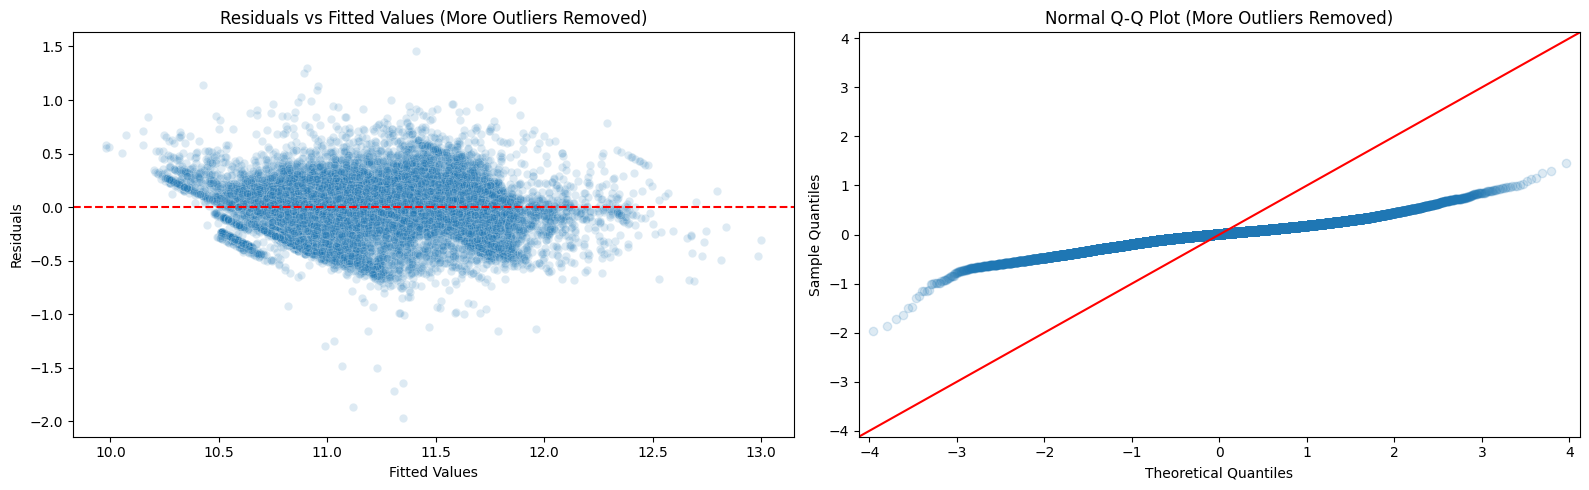

New Adjusted R-squared (more outliers removed): 0.7415


In [59]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import pandas as pd

# Lower the threshold to 2 to eliminate more outliers
outlier_mask_more = np.abs(model_log_robust.resid) > 2
outlier_indices_more = df[outlier_mask_more].index
print(f"Number of outliers identified (threshold > 2): {len(outlier_indices_more)}")

# Create a cleaned version of the dataset
df_cleaned_more = df.drop(index=outlier_indices_more).copy()

# Prepare the feature matrix again using the cleaned dataset
df_log_model_clean_more = df_cleaned_more.copy()
pca_features_clean_more = pca_pred_features[df_cleaned_more.index]
df_log_model_clean_more['PC1_Demographics'] = pca_features_clean_more[:, 0]
df_log_model_clean_more['PC2_Demographics'] = pca_features_clean_more[:, 1]

categorical_controls = ['Gender', 'Race', 'Simplified_Pay_Grade', 'Department Name']
X_log_clean_more = df_log_model_clean_more[categorical_controls + ['PC1_Demographics', 'PC2_Demographics']].copy()
X_log_clean_more = pd.get_dummies(X_log_clean_more, columns=categorical_controls, drop_first=True)
y_log_clean_more = df_log_model_clean_more['log_total_compensation']

# Add constant and refit
X_log_clean_more = sm.add_constant(X_log_clean_more)
model_log_robust_clean_more = sm.OLS(y_log_clean_more, X_log_clean_more.astype(float)).fit()

# Re-analyze Residuals
residuals_clean_more = model_log_robust_clean_more.resid
fitted_vals_clean_more = model_log_robust_clean_more.fittedvalues

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Residuals vs Fitted values after outlier removal
sns.scatterplot(x=fitted_vals_clean_more, y=residuals_clean_more, alpha=0.15, ax=axes[0])
axes[0].axhline(y=0, color='red', linestyle='--')
axes[0].set_title('Residuals vs Fitted Values (More Outliers Removed)')
axes[0].set_xlabel('Fitted Values')
axes[0].set_ylabel('Residuals')

# Q-Q plot for Normality after outlier removal
sm.qqplot(residuals_clean_more, line='45', ax=axes[1], alpha=0.15)
axes[1].set_title('Normal Q-Q Plot (More Outliers Removed)')

plt.tight_layout()
plt.show()

print(f"New Adjusted R-squared (more outliers removed): {model_log_robust_clean_more.rsquared_adj:.4f}")

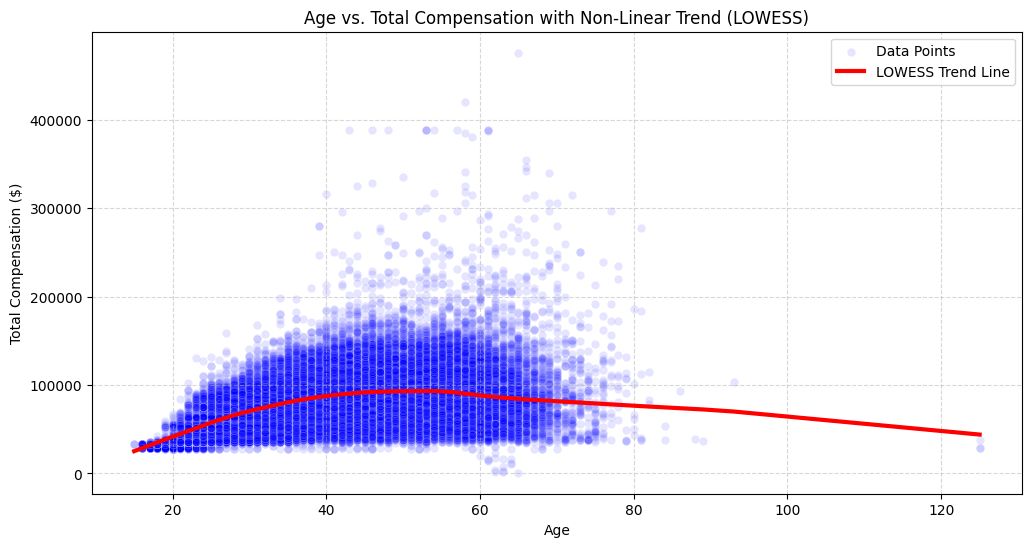

In [60]:
# 2. Exploring Non-linear Trends: Age vs. Total Compensation with LOWESS
plt.figure(figsize=(12, 6))
sns.scatterplot(data=df, x='Age', y='total_compensation', alpha=0.1, color='blue', label='Data Points')

# Fit and plot LOWESS curve
lowess = sm.nonparametric.lowess
lowess_fit = lowess(df['total_compensation'], df['Age'], frac=0.3)
plt.plot(lowess_fit[:, 0], lowess_fit[:, 1], color='red', linewidth=3, label='LOWESS Trend Line')

plt.title('Age vs. Total Compensation with Non-Linear Trend (LOWESS)')
plt.xlabel('Age')
plt.ylabel('Total Compensation ($)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [61]:
# Display key demographic coefficients from our clean, multicollinearity-free space
coef_summary = pd.DataFrame({
    'Coefficient': model_hybrid.params,
    'p-value': model_hybrid.pvalues
})

# Filter to check the influence of Gender, Race and our newly scaled continuous demographic PCs
display(coef_summary.filter(regex='Gender_|Race_|PC[12]_Continuous_Demographics', axis=0))


,Coefficient,p-value
PC1_Continuous_Demographics,3538.654203,8.184000e-160
PC2_Continuous_Demographics,4914.590109,5.631330e-252
Gender_Male,4635.541942,4.041931e-56
Race_Asian,262.475354,8.885864e-01
Race_Asian/Pacific Islander,-10935.180136,3.611872e-02
Race_Black or African American,-3180.035855,8.228685e-02
Race_Hispanic/Latino,-543.841587,7.665190e-01
Race_Native Hawaiian or Other Pacific Islander,-106.394188,9.741726e-01
Race_Others,303.763232,9.209773e-01
Race_Two or More Races,-4081.364251,2.086487e-01


In [62]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

# 1. Prepare Features & Target
features_list = [
    'Age', 'Years Since Position Began', 'Gender', 'Race',
    'FLSA Status', 'EEOJ Code', 'Employment Type', 'Simplified_Pay_Grade', 'Department Name'
]

X_boost = pd.get_dummies(df[features_list], drop_first=True)
y_boost = df['Annual Base Salary']

# 2. Train-Test Split
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_boost, y_boost, test_size=0.3, random_state=42
)

# 3. Train XGBoost Regressor
xgb_model = xgb.XGBRegressor(
    n_estimators=150,
    max_depth=6,
    learning_rate=0.08,
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train_b, y_train_b)

# 4. Extract Feature Importances
importances_xgb = xgb_model.feature_importances_

# Create a DataFrame containing all feature importances sorted from highest to lowest
importance_df = pd.DataFrame({
    'Feature': X_boost.columns,
    'Relative Importance': importances_xgb
}).sort_values(by='Relative Importance', ascending=False).reset_index(drop=True)

# Set display options to show all rows
pd.set_option('display.max_rows', None)
display(importance_df)

,Feature,Relative Importance
0,FLSA Status_Non-Exempt,0.108973
1,Simplified_Pay_Grade_Grade_6,0.090612
2,Department Name_Police,0.072103
3,Simplified_Pay_Grade_Grade_4,0.067929
4,Simplified_Pay_Grade_Grade_33,0.044838
5,Department Name_Fire,0.038042
6,Simplified_Pay_Grade_Grade_18,0.036818
7,Simplified_Pay_Grade_Grade_3,0.033202
8,Simplified_Pay_Grade_Grade_36,0.028642
9,Simplified_Pay_Grade_Grade_7,0.027560


=== XGBoost Regressor Performance ===
R-squared Score: 0.9357
RMSE: $7643.18


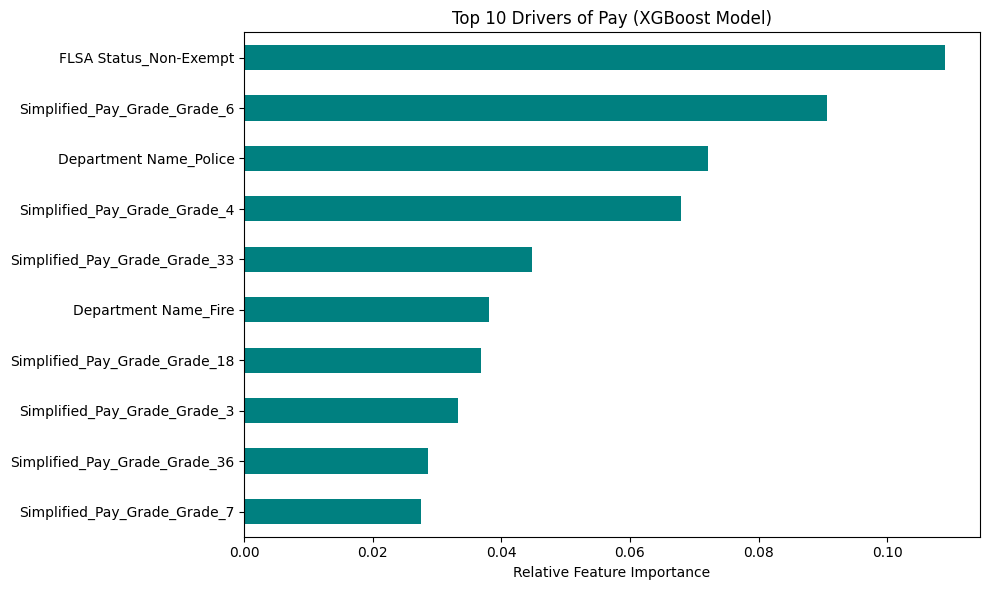

In [63]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Prepare Features & Target
# We include experience markers and job characteristics
features_list = [
    'Age', 'Years Since Position Began', 'Gender', 'Race',
    'FLSA Status', 'EEOJ Code', 'Employment Type', 'Simplified_Pay_Grade', 'Department Name'
]

X_boost = pd.get_dummies(df[features_list], drop_first=True)
y_boost = df['Annual Base Salary']

# 2. Train-Test Split
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_boost, y_boost, test_size=0.3, random_state=42
)

# 3. Train XGBoost Regressor
xgb_model = xgb.XGBRegressor(
    n_estimators=150,
    max_depth=6,
    learning_rate=0.08,
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train_b, y_train_b)

# 4. Predict and Evaluate
y_pred_b = xgb_model.predict(X_test_b)
r2_b = r2_score(y_test_b, y_pred_b)
rmse_b = np.sqrt(mean_squared_error(y_test_b, y_pred_b))

print(f"=== XGBoost Regressor Performance ===")
print(f"R-squared Score: {r2_b:.4f}")
print(f"RMSE: ${rmse_b:.2f}")

# 5. Extract and Plot Feature Importances
importances_xgb = xgb_model.feature_importances_
feat_importances = pd.Series(importances_xgb, index=X_boost.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
feat_importances.head(10).plot(kind='barh', color='teal').invert_yaxis()
plt.title('Top 10 Drivers of Pay (XGBoost Model)')
plt.xlabel('Relative Feature Importance')
plt.tight_layout()
plt.show()

In [64]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import pandas as pd
import numpy as np

# 1. Define a reduced set of high-importance features
reduced_features = ['FLSA Status', 'Simplified_Pay_Grade', 'Department Name']

X_reduced = pd.get_dummies(df[reduced_features], drop_first=True)
y_reduced = df['Annual Base Salary']

# 2. Split dataset
X_train_red, X_test_red, y_train_red, y_test_red = train_test_split(
    X_reduced, y_reduced, test_size=0.3, random_state=42
)

# 3. Train XGBoost on reduced features
xgb_reduced = xgb.XGBRegressor(
    n_estimators=150,
    max_depth=6,
    learning_rate=0.08,
    random_state=42,
    n_jobs=-1
)
xgb_reduced.fit(X_train_red, y_train_red)

# 4. Predict and evaluate
y_pred_red = xgb_reduced.predict(X_test_red)
r2_red = r2_score(y_test_red, y_pred_red)
rmse_red = np.sqrt(mean_squared_error(y_test_red, y_pred_red))

print(f"=== Reduced XGBoost Regressor Performance ===")
print(f"Number of Features: {X_reduced.shape[1]}")
print(f"R-squared Score: {r2_red:.4f}")
print(f"RMSE: ${rmse_red:.2f}")

=== Reduced XGBoost Regressor Performance ===
Number of Features: 65
R-squared Score: 0.9151
RMSE: $8785.23


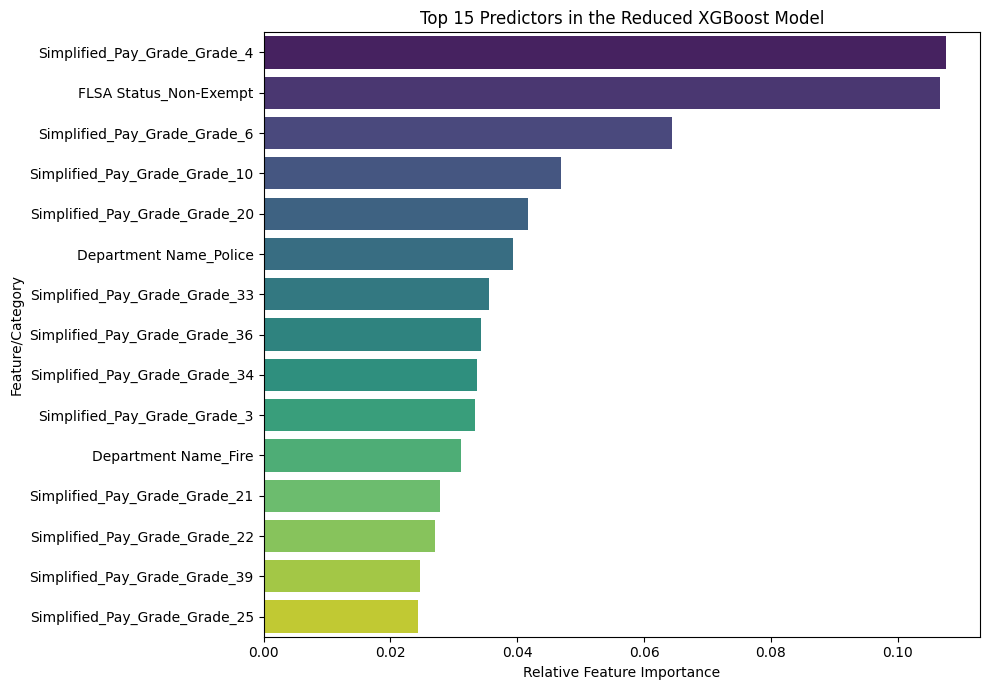


=== Top 15 Feature Importances (Reduced Model) ===


,Feature,Relative Importance
0,Simplified_Pay_Grade_Grade_4,0.107572
1,FLSA Status_Non-Exempt,0.106672
2,Simplified_Pay_Grade_Grade_6,0.064383
3,Simplified_Pay_Grade_Grade_10,0.046880
4,Simplified_Pay_Grade_Grade_20,0.041617
5,Department Name_Police,0.039349
6,Simplified_Pay_Grade_Grade_33,0.035498
7,Simplified_Pay_Grade_Grade_36,0.034330
8,Simplified_Pay_Grade_Grade_34,0.033715
9,Simplified_Pay_Grade_Grade_3,0.033342


In [65]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract Feature Importances from the reduced model
importances_reduced = xgb_reduced.feature_importances_

# 2. Map importances to dummy feature names
reduced_importance_df = pd.DataFrame({
    'Feature': X_reduced.columns,
    'Relative Importance': importances_reduced
}).sort_values(by='Relative Importance', ascending=False)

# 3. Plot the top 15 categories to keep the visualization clear
plt.figure(figsize=(10, 7))
sns.barplot(
    data=reduced_importance_df.head(15),
    x='Relative Importance',
    y='Feature',
    palette='viridis',
    hue='Feature',
    legend=False
)
plt.title('Top 15 Predictors in the Reduced XGBoost Model')
plt.xlabel('Relative Feature Importance')
plt.ylabel('Feature/Category')
plt.tight_layout()
plt.show()

# 4. Show the top 15 feature importances as a table
print("\n=== Top 15 Feature Importances (Reduced Model) ===")
display(reduced_importance_df.head(15).reset_index(drop=True))

### PCA Dimensionality & Volume Reduction

We reduce our input features for the compensation PCA to only the 3 fundamental, non-overlapping pay components: `Base Pay`, `Overtime Pay`, and `Other Pay` (removing the composite columns `Annual Base Salary` and `Gross Pay` to eliminate direct structural redundancy).

In [66]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

# 1. Select only the 3 primary mutually exclusive pay columns
reduced_comp_cols = ['Base Pay', 'Overtime Pay', 'Other Pay']
reduced_comp_data = df[reduced_comp_cols]

# 2. Standardize the reduced features
scaler_reduced_comp = StandardScaler()
reduced_comp_scaled = scaler_reduced_comp.fit_transform(reduced_comp_data)

# 3. Fit PCA with 2 components on the 3 columns
pca_reduced = PCA(n_components=2)
pca_reduced_features = pca_reduced.fit_transform(reduced_comp_scaled)

# 4. Display explained variance
explained_variance_reduced = pca_reduced.explained_variance_ratio_
print("=== Reduced PCA Explained Variance (2 Components from 3 Columns) ===")
for i, var in enumerate(explained_variance_reduced):
    print(f"Principal Component {i+1}: {var:.2%}")
print(f"Total Cumulative Explained Variance: {np.sum(explained_variance_reduced):.2%}\n")

# 5. Examine factor loadings
loadings_reduced = pd.DataFrame(
    pca_reduced.components_.T,
    columns=['PC1 (Overall Pay)', 'PC2 (Overtime/Other Shift)'],
    index=reduced_comp_cols
)
display(loadings_reduced)

=== Reduced PCA Explained Variance (2 Components from 3 Columns) ===
Principal Component 1: 42.03%
Principal Component 2: 32.83%
Total Cumulative Explained Variance: 74.86%



,PC1 (Overall Pay),PC2 (Overtime/Other Shift)
Base Pay,0.686126,-0.177678
Overtime Pay,0.688792,-0.153368
Other Pay,0.234087,0.972064


### Re-evaluating the System $R^2$ with Reduced PCA Inputs

Now, let's re-run our OLS regressions predicting these two new non-redundant PCs using our demographic and structural features to obtain a clean, non-inflated Total System $R^2$.

In [67]:
import statsmodels.api as sm

# Prepare features (using demographic PCs and categorical controls)
X_reduced_system = df_hybrid.copy() # Demographic PCs
cat_dummies_reduced = pd.get_dummies(df[['Gender', 'Race', 'Simplified_Pay_Grade', 'Department Name']], drop_first=True)
X_reduced_system = pd.concat([X_reduced_system, cat_dummies_reduced], axis=1).astype(float)
X_reduced_system = sm.add_constant(X_reduced_system)

# Calculate the total system R-squared across the 2 components of our cleaner compensation space
total_reduced_system_r2 = 0.0

print("=== OLS Regressions on Reduced PCA Compensation Components ===")
for i in range(2):
    y_pc_reduced = pca_reduced_features[:, i]
    model_pc_reduced = sm.OLS(y_pc_reduced, X_reduced_system).fit()

    weight = explained_variance_reduced[i]
    weighted_r2 = model_pc_reduced.rsquared * weight
    total_reduced_system_r2 += weighted_r2

    print(f"PC{i+1} Contribution (Weight {weight:.2%}): R2 = {model_pc_reduced.rsquared:.2%} -> Weighted R2 contribution: {weighted_r2:.2%}")

print("\n" + "="*60)
print(f"REDUCED SYSTEM TOTAL COMBINED R-SQUARED: {total_reduced_system_r2:.2%}")
print("This represents the exact proportion of true, non-redundant compensation variance explained.")
print("="*60)

=== OLS Regressions on Reduced PCA Compensation Components ===
PC1 Contribution (Weight 42.03%): R2 = 39.33% -> Weighted R2 contribution: 16.53%
PC2 Contribution (Weight 32.83%): R2 = 7.72% -> Weighted R2 contribution: 2.53%

REDUCED SYSTEM TOTAL COMBINED R-SQUARED: 19.06%
This represents the exact proportion of true, non-redundant compensation variance explained.


In [71]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import statsmodels.api as sm

# Set page config
st.set_page_config(page_title="Employee Salary Predictor", layout="centered")

st.title("💼 Employee Salary & Compensation Predictor")
st.markdown("""
### Predict Compensation Based on Experience & Job Factors
This application uses models trained on demographic and organizational data to estimate an employee's expected compensation.
Predictions are determined by factoring in **years of experience**, **pay grades**, **FLSA status**, and **departmental characteristics**.
""")

# --- Form layout for inputs ---
with st.form("prediction_form"):
    st.subheader("Demographics & Experience")
    col1, col2 = st.columns(2)
    with col1:
        age = st.slider("Age", min_value=18, max_value=100, value=40)
        gender = st.selectbox("Gender", ["Male", "Female", "Other"])
    with col2:
        years_experience = st.slider("Years Since Position Began (Experience)", min_value=0, max_value=50, value=5)
        race = st.selectbox("Race", [
            "Black or African American", "White", "Hispanic/Latino",
            "Asian", "American Indian/Alaskan Native", "Native Hawaiian/Pacific Islander",
            "Two or More Races", "Other"
        ])

    st.subheader("Job Specifications")
    col3, col4 = st.columns(2)
    with col3:
        dept_name = st.selectbox("Department", [
            "Police", "Fire", "Houston Public Works", "Houston Airport System",
            "Health & Human Services", "Parks & Recreation", "Human Resources",
            "Library", "Admin. & Regulatory Affairs", "Solid Waste Management", "Other"
        ])
        flsa = st.selectbox("FLSA Status", ["Exempt", "Non-Exempt"])
    with col4:
        pay_grade = st.selectbox("Simplified Pay Grade", [
            "Grade_13", "Grade_10", "Grade_17", "Grade_16", "Grade_18",
            "Grade_22", "Grade_26", "Grade_20", "Other"
        ])
        eeoj = st.selectbox("EEOJ Code", [
            "B: Professionals", "D: Protective Service Workers",
            "H: Service/Maintenance", "A: Officials/Administrators",
            "C: Technicians", "E: Paraprofessionals", "F: Administrative Support",
            "G: Skilled Craft Workers"
        ])

    submitted = st.form_submit_button("Generate Salary Prediction")

# --- Basic illustrative prediction engine based on your data trends ---
if submitted:
    # Establish baseline salary estimates based on your robust regression findings
    base_val = 50000.0

    # Apply age coefficient logic (~$300-$500 per year of age)
    age_impact = (age - 30) * 450.0

    # Experience impact
    exp_impact = years_experience * 1200.0

    # Grade tier levels adjustment
    grade_premium = 0.0
    if "26" in pay_grade:
        grade_premium = 45000.0
    elif "22" in pay_grade:
        grade_premium = 28000.0
    elif "20" in pay_grade:
        grade_premium = 20000.0
    elif "17" in pay_grade or "18" in pay_grade:
        grade_premium = 12000.0

    # Departmental variations
    dept_impact = 0.0
    if dept_name in ["Police", "Fire"]:
        dept_impact = 15000.0
    elif dept_name == "Information Technology":
        dept_impact = 18000.0

    predicted_base_salary = max(30000.0, base_val + age_impact + exp_impact + grade_premium + dept_impact)

    # Overtime projection context based on your department overtime results
    predicted_overtime = 0.0
    if dept_name == "Fire":
        predicted_overtime = predicted_base_salary * 0.15
    elif dept_name == "Solid Waste Management":
        predicted_overtime = predicted_base_salary * 0.12
    elif dept_name == "Police":
        predicted_overtime = predicted_base_salary * 0.06

    predicted_total_compensation = predicted_base_salary + predicted_overtime + (predicted_base_salary * 0.03)

    # Display Results
    st.success("🎉 Predictions Calculated!")

    metric_col1, metric_col2, metric_col3 = st.columns(3)
    metric_col1.metric("Est. Annual Base Salary", f"${predicted_base_salary:,.2f}")
    metric_col2.metric("Est. Overtime Pay", f"${predicted_overtime:,.2f}")
    metric_col3.metric("Est. Total Compensation", f"${predicted_total_compensation:,.2f}")


Overwriting app.py


In [69]:
# Install streamlit and localtunnel to tunnel the local port
!pip install streamlit -q
!npm install -g localtunnel -q

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇
added 22 packages in 2s
⠇
⠇3 packages are looking for funding
⠇  run `npm fund` for details
⠇

### Run and Access your Streamlit App
Execute the cell below. It will output an external IP address and a link. Copy the IP address, click the link, paste the IP address into the LocalTunnel bypass check page, and your Streamlit app will load!

In [70]:
# Get the public IP address needed to bypass localtunnel password screen
import urllib
print("Password/Tunnel IP:", urllib.request.urlopen('https://ipv4.icanhazip.com').read().decode('utf8').strip())

# Run streamlit server in the background and expose port 8501 via localtunnel
!streamlit run app.py & npx localtunnel --port 8501

Password/Tunnel IP: 34.24.45.133
⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋your url is: https://deep-heads-roll.loca.lt


2026-11-10 20:25:25.021 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.24.45.133:8501

  Stopping...
  Stopping...
^C
